# Nenadgledano mašinsko učenje na MNIST i Fashion-MNIST
### Celokupan izveštaj: algoritmi, rezultati i analiza

**Istraživačko pitanje:** koliko dobro različite tehnike nenadgledanog učenja otkrivaju strukturu u slikama bez
ikakvih oznaka, i zašto je Fashion-MNIST teži od MNIST-a?

**Kako je izveštaj organizovan.** Za svaki algoritam redom:
1. **Šta je:** ideja, koraci i matematika;
2. **Zašto ga koristimo:** njegova uloga u projektu;
3. **Demonstracija:** mali primer koji se računa u ovom notebooku (2D podaci ili uzorak od 3.000 MNIST slika);
4. **Rezultati u projektu:** grafici i tabele koje pravi `glavni.py` na celim skupovima (70.000 slika po skupu), uz tumačenje.

**Oznake klasa algoritmi nikad ne vide.** Koriste se samo za bojenje grafika i za merenje kvaliteta na kraju.

### Glavni nalazi

1. **Reprezentacija je važnija od algoritma.** Isti K-means na MNIST-u daje tačnost 0.53 na sirovim pikselima, a 0.93
   u prostoru dobijenom UMAP-om na osobinama autoenkodera (pristup N2D). Razlike između algoritama u istom prostoru
   su mnogo manje.
2. **Naučene reprezentacije traže dovoljno podataka.** Na malom uzorku N2D ne donosi prednost u odnosu na običan UMAP,
   a na celom MNIST-u je ubedljivo najbolji.
3. **Fashion-MNIST je ograničen sličnošću klasa, a ne količinom podataka.** Najbolja tačnost je oko 0.61 i ne raste sa
   boljim reprezentacijama: majica, košulja, džemper i kaput, kao i sandala, patika i čizma, na 28×28 piksela imaju
   skoro istu siluetu.
4. **Zamena klasa nije uvek sličnost.** Kada se jedna klasa podeli na dva klastera, a dve druge spoje u jedan,
   uparivanje klastera sa klasama pravi „zamene" bez ikakve vizuelne sličnosti (npr. „1 → 9").

### Sadržaj

1. Podaci — slika kao tačka, rastojanje i susedi
2. Smanjenje dimenzionalnosti — PCA, t-SNE, UMAP, autoenkoder, N2D, poređenje, četiri prostora za klasterovanje
3. Klasterovanje — K-means, GMM, aglomerativno (Ward), mere kvaliteta, rezultati
4. Analiza grešaka — koje klase se mešaju i artefakt uparivanja
5. Zaključak — zaključci, ograničenja, šta je isprobano i izbačeno, pregled algoritama
6. Literatura

## Pokretanje

Rezultati korišćeni u izveštaju nastaju komandom (iz foldera projekta, u okruženju `venv`):

```
python glavni.py --dataset oba                # ceo projekat (delovi 1, 2 i 3), 70.000 slika po skupu
python glavni.py --dataset oba --n 10000      # brža verzija na uzorku
python glavni.py --dataset oba --delovi 2 3   # samo pojedini delovi (koristi keš iz dela 1)
python glavni.py --dataset digits --brzo      # brza proba bez interneta
```

Delovi koda i odeljci izveštaja: deo 1 (`deo1_dimenzionalnost.py`) je odeljak 2, deo 2 (`deo2_klasterovanje.py`)
odeljak 3, a deo 3 (`deo3_analiza.py`) odeljak 4. Ovaj notebook ne trenira modele na celim skupovima, već samo
učitava rezultate iz `rezultati/` i računa male demonstracije (oko dva minuta uz GPU).

In [1]:
import warnings
warnings.filterwarnings("ignore")   # pre uvoza biblioteka, da se ne ispisuju njihova upozorenja

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import umap
from IPython.display import Image, Markdown, display
from matplotlib.patches import Ellipse
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from scipy.signal import correlate2d
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler

import autoenkoder as ae
from metrike import tacnost
from podaci import ucitaj_sve, uzorak

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})
BOJE = plt.get_cmap("tab10")
UREDJAJ = "cuda" if torch.cuda.is_available() else "cpu"

# rezultati projekta (glavni.py)
R = Path("rezultati")
SKUPOVI = {"mnist": "MNIST", "fashion": "Fashion-MNIST"}
sazetak = {s: json.loads((R / s / "sazetak.txt").read_text(encoding="utf-8")) for s in SKUPOVI}
klasterovanje = {s: pd.read_csv(R / s / "2_rezultati_klasterovanja.csv") for s in SKUPOVI}

# mali uzorak za demonstracije
X_sve, y_sve, nazivi, vel = ucitaj_sve("mnist")
idx = uzorak(len(X_sve), 3000, seed=0)
X, y = X_sve[idx], y_sve[idx]


def slika(skup, ime, sirina=850):
    display(Image(filename=str(R / skup / ime), width=sirina))


def oba_skupa(ime, sirina=850):
    for s, naziv in SKUPOVI.items():
        display(Markdown(f"**{naziv}**"))
        slika(s, ime, sirina)


def rasipanje(ax, Z, oznake, naslov, s=4):
    for c in np.unique(oznake):
        m = oznake == c
        ax.scatter(Z[m, 0], Z[m, 1], s=s, color=BOJE(int(c) % 10), label=str(c))
    ax.set_title(naslov); ax.set_xticks([]); ax.set_yticks([])


def mreza(redovi, naslovi_redova, n=8):
    fig, axes = plt.subplots(len(redovi), n, figsize=(1.3 * n, 1.45 * len(redovi)), squeeze=False)
    for i, (red, nas) in enumerate(zip(redovi, naslovi_redova)):
        for j in range(n):
            axes[i, j].imshow(np.asarray(red[j]).reshape(28, 28), cmap="gray_r")
            axes[i, j].axis("off")
        axes[i, 0].set_title(nas, fontsize=9, loc="left")
    plt.tight_layout(); plt.show()


print({naziv: sazetak[s]["uzorak"] for s, naziv in SKUPOVI.items()}, "slika po skupu u projektu")
print("uzorak za demonstracije:", X.shape, "| uređaj:", UREDJAJ)

Učitavam mnist_784 sa OpenML-a (prvi put traje duže, posle se čita iz keša)...


{'MNIST': 70000, 'Fashion-MNIST': 70000} slika po skupu u projektu
uzorak za demonstracije: (3000, 784) | uređaj: cuda


## 1. Podaci

Oba skupa imaju po 70.000 crno-belih slika veličine 28×28 piksela i po 10 klasa sa podjednakim brojem primera.
Pikseli su skalirani na opseg [0, 1] (0 = belo, 1 = crno).

| | MNIST | Fashion-MNIST |
|---|---|---|
| Sadržaj | rukom pisane cifre | odevni predmeti iz Zalando kataloga |
| Klase | 0, 1, …, 9 | majica, pantalone, džemper, haljina, kaput, sandala, košulja, patika, torba, čizma |
| Izvor razlika unutar klase | rukopis (nagib, debljina, oblik) | modeli, šare, materijali |
| Šta otežava zadatak | slične cifre (4/9, 3/5/8) | slične siluete (majica/košulja/džemper/kaput, sandala/patika/čizma) |

Oba skupa postavljaju **klasifikacioni problem** sa 10 klasa, ali ga projekat ne rešava direktno: algoritmi dobijaju
samo slike, traže grupe sličnih slika, a oznake služe tek na kraju kao „tačan odgovor" za proveru. Pitanje projekta je
**koliko klasifikacione strukture algoritmi mogu da otkriju sami**. Fashion-MNIST je napravljen kao teža zamena za
MNIST: isti format, ali veće razlike unutar klasa i manje između nekih klasa.

Učitavam Fashion-MNIST sa OpenML-a (prvi put traje duže, posle se čita iz keša)...


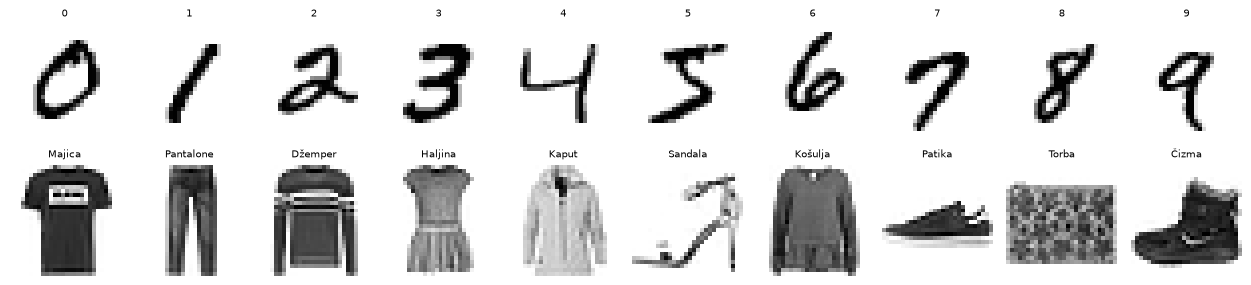

In [2]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for red, s in enumerate(SKUPOVI):
    Xs, ys, nz, _ = (X_sve, y_sve, nazivi, vel) if s == "mnist" else ucitaj_sve(s)
    for c in range(10):
        axes[red, c].imshow(Xs[np.where(ys == c)[0][0]].reshape(28, 28), cmap="gray_r")
        axes[red, c].set_title(nz[c], fontsize=8); axes[red, c].axis("off")
plt.tight_layout(); plt.show()

### 1.1 Slika kao tačka: rastojanje i susedi

Skoro svi algoritmi u projektu se oslanjaju na pojam **suseda**, pa ga objašnjavamo prvo.

- Slika 28×28 je niz od **784 broja**, odnosno **tačka u prostoru sa 784 dimenzije** (kao što tačka na mapi ima 2 koordinate).
- **Euklidsko rastojanje** poredi dve slike piksel po piksel:
  $$d(a, b) = \sqrt{\sum_{p=1}^{784} (a_p - b_p)^2}$$
  Malo rastojanje znači da slike imaju mastilo na sličnim mestima, odnosno da liče jedna na drugu.
- **Susedi** neke slike su slike sa najmanjim rastojanjem do nje („15 najbližih suseda" = 15 najsličnijih slika).

Primer sa slikama od 4 piksela (2×2):

| slika | pikseli | rastojanje do A |
|---|---|---|
| A | (1, 0, 1, 0) | — |
| B | (1, 0, 1, 1) | $\sqrt{1} = 1$: razlikuju se u jednom pikselu, susedi |
| C | (0, 1, 0, 1) | $\sqrt{4} = 2$: razlikuju se u svim pikselima, daleko |

**Demonstracija:** jedna četvorka iz uzorka, njenih 8 najbližih i 3 najdalja suseda (crveno = druga cifra).

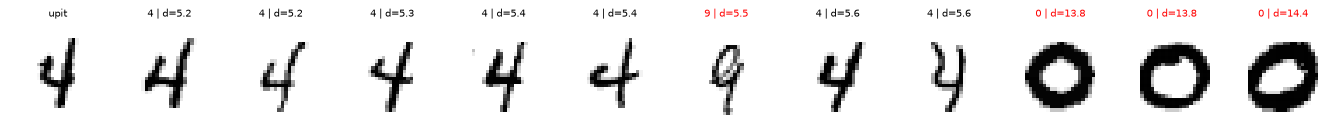

udeo od 10 najbližih suseda iz iste klase (uzorak od 3.000 slika): 84.2%


In [3]:
q = np.where(y == 4)[0][3]
d = np.sqrt(((X - X[q]) ** 2).sum(1))
red = np.argsort(d)
izbor = [q] + list(red[1:9]) + list(red[-3:])
fig, axes = plt.subplots(1, len(izbor), figsize=(15, 1.9))
for ax, i in zip(axes, izbor):
    ax.imshow(X[i].reshape(28, 28), cmap="gray_r"); ax.axis("off")
    ax.set_title("upit" if i == q else f"{y[i]} | d={d[i]:.1f}", fontsize=8,
                 color="black" if i == q or y[i] == 4 else "red")
plt.tight_layout(); plt.show()

sq = (X ** 2).sum(1)
D2 = sq[:, None] + sq[None, :] - 2 * X @ X.T
np.fill_diagonal(D2, np.inf)
susedi10 = np.argsort(D2, axis=1)[:, :10]
print(f"udeo od 10 najbližih suseda iz iste klase (uzorak od 3.000 slika): {(y[susedi10] == y[:, None]).mean():.1%}")

Velika većina suseda je ista cifra, pa slike iste klase uglavnom „žive u istom kraju". Na većem skupu udeo je još
veći, jer svaka slika ima bliže primere. Greške su tipično slične cifre: četvorka sa zatvorenim vrhom liči na devetku.

**Ograničenje:** rastojanje piksel po piksel ne razume oblik. Ista cifra pomerena za dva piksela ima mastilo na drugim
pikselima, pa izgleda „daleko", dok se 4 i 9 razlikuju u svega par piksela na vrhu. Zato su korisne reprezentacije koje
**uče** osobine oblika (autoenkoder, odeljak 2.4).

## 2. Smanjenje dimenzionalnosti (deo 1)

**Zašto smanjujemo dimenzionalnost:**
1. **784 broja su suvišna.** Ivice slike su skoro uvek bele, a susedni pikseli skoro uvek slični. Stvarnih
   „stepeni slobode" (nagib, debljina, oblik petlje) ima mnogo manje.
2. **Prokletstvo dimenzionalnosti.** U mnogo dimenzija rastojanja postaju slična (svaka tačka je približno jednako
   daleko od svih), pa algoritmi zasnovani na rastojanju slabije razlikuju bliske i daleke tačke.
3. **Brzina i vizuelizacija.** Na 10–50 brojeva algoritmi rade mnogo brže, a 2D se može nacrtati.

Cilj je malo brojeva po slici koji čuvaju ono bitno. Metode se razlikuju po tome **šta smatraju bitnim**:

| Metoda | Linearna? | Šta čuva | Uloga u projektu |
|---|---|---|---|
| PCA | da | ukupnu varijansu (velike razlike) | prostor **PCA-50**, ulaz za t-SNE, polazna linearna metoda |
| t-SNE | ne | bliske susede | samo 2D vizuelizacija |
| UMAP | ne | susede i deo globalne strukture | prostor **UMAP-10**, 2D vizuelizacija |
| Autoenkoder | ne | sve što je potrebno za rekonstrukciju | prostor **AE-10** |
| N2D (AE + UMAP) | ne | susede u prostoru naučenih osobina | prostor **AE-UMAP-10** |

### 2.1 PCA (analiza glavnih komponenti)

#### Šta je

**Ideja:** pronađi pravce u kojima se slike najviše razlikuju i opiši svaku sliku samo preko njih.

1. Oduzmi **prosečnu sliku** $\bar{x}$ od svih slika.
2. Izračunaj **kovarijansnu matricu** $C$ (784×784).
3. Nađi njene **sopstvene vektore** (glavne komponente) i **sopstvene vrednosti** (varijansa duž svakog pravca).
4. Zadrži $k$ pravaca sa najvećom varijansom; to su kolone matrice $W_k$ (784 × $k$).
5. **Projekcija:** $z = W_k^\top (x - \bar{x})$, pa slika postaje $k$ brojeva.
6. **Rekonstrukcija:** $\hat{x} = \bar{x} + W_k z$, odnosno put nazad do slike.

**+** brza (sekunda za 70.000 slika), egzaktno rešenje, uvek isti rezultat, ima rekonstrukciju, komponente se mogu
protumačiti  **−** vidi samo linearnu strukturu; velika varijansa nije isto što i razlika između klasa

#### Kovarijansna matrica

$$C_{ij} = \frac{1}{n-1} \sum_{\text{slike}} (x_i - \bar{x}_i)(x_j - \bar{x}_j)$$

Za svaki par piksela pokazuje da li se menjaju zajedno:

| Znak $C_{ij}$ | Značenje | Primer kod MNIST-a |
|---|---|---|
| pozitivan | kada je jedan piksel taman, i drugi je obično taman | dva susedna piksela (crta je šira od jednog piksela) |
| blizu 0 | nemaju veze | piksel u uglu (uvek beo) i bilo koji drugi |
| negativan | kada je jedan taman, drugi je obično svetao | centar slike i tačke levo i desno od njega |

Dijagonala ($C_{ii}$) je varijansa svakog piksela, a matrica je simetrična ($C_{ij} = C_{ji}$).

- Mreža blokova na svakih 28 polja: pikseli su spljošteni red po red, pa se vide veze između redova slike.
- Desno: kada je centar taman, taman je i kosi potez kroz njega (crveno), a strane su svetle (plavo). To je razlika
  između **jedinice** (mastilo u sredini) i **nule** (mastilo sa strana). PCA iz ove matrice izvlači upravo takve obrasce.

#### Sopstveni vektori su pravci najveće varijanse

Ako slike projektujemo na pravac $w$ dužine 1, varijansa projekcija je $\text{Var}(w^\top x) = w^\top C\, w$.

- Najveća je za **sopstveni vektor** matrice $C$ sa najvećom sopstvenom vrednošću ($C w = \lambda w$) i tada iznosi
  $\lambda_1$; to je **PC1**.
- Sledeći najbolji pravac, **normalan na prvi**, je sopstveni vektor sa $\lambda_2$ (**PC2**), i tako redom.
- Kolone $W$ su **ortonormirane** ($W_k^\top W_k = I$): $W$ je novi, okrenut koordinatni sistem, pa ista matrica
  radi i u projekciji ($W_k^\top$) i u rekonstrukciji ($W_k$). U scikit-learn-u je `pca.components_` = $W_k^\top$.

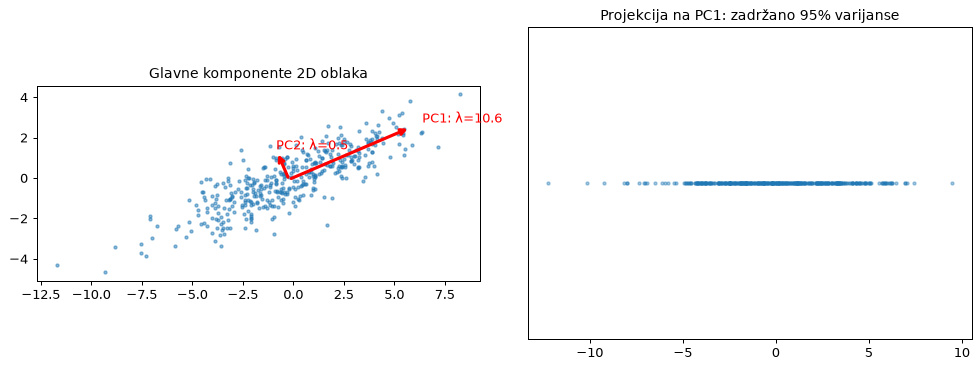

W (kolone su PC1 i PC2):
 [[ 0.92 -0.39]
 [ 0.39  0.92]]


In [5]:
rng = np.random.default_rng(0)
T = rng.normal(size=(400, 2)) @ np.array([[3, 1.2], [0, 0.8]])
pca2 = PCA(2).fit(T)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(T[:, 0], T[:, 1], s=6, alpha=0.5)
for duz, vek, ime in zip(pca2.explained_variance_, pca2.components_, ["PC1", "PC2"]):
    v = vek * 2 * np.sqrt(duz)
    axes[0].annotate("", pca2.mean_ + v, pca2.mean_, arrowprops=dict(arrowstyle="->", lw=2.5, color="red"))
    axes[0].text(*(pca2.mean_ + v * 1.1), f"{ime}: λ={duz:.1f}", color="red", fontsize=10)
axes[0].set_aspect("equal"); axes[0].set_title("Glavne komponente 2D oblaka")
Z = pca2.transform(T)
axes[1].scatter(Z[:, 0], np.zeros_like(Z[:, 0]), s=6, alpha=0.4)
axes[1].set_yticks([]); axes[1].set_title(f"Projekcija na PC1: zadržano {pca2.explained_variance_ratio_[0]:.0%} varijanse")
plt.tight_layout(); plt.show()
print("W (kolone su PC1 i PC2):\n", pca2.components_.T.round(2))

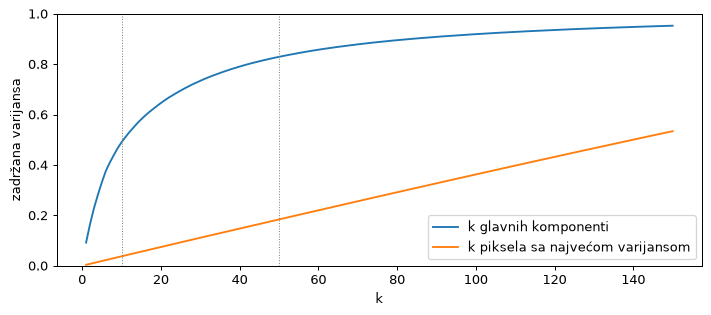

k=50: komponente 83%, pikseli 18%


In [6]:
pca = PCA().fit(X)
var_px = np.sort(X.var(0))[::-1]
ks = np.arange(1, 151)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ks, np.cumsum(pca.explained_variance_ratio_)[:150], label="k glavnih komponenti")
ax.plot(ks, np.cumsum(var_px)[:150] / var_px.sum(), label="k piksela sa najvećom varijansom")
for k in (10, 50):
    ax.axvline(k, c="gray", ls=":", lw=0.8)
ax.set_xlabel("k"); ax.set_ylabel("zadržana varijansa"); ax.legend(); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()
print(f"k=50: komponente {np.cumsum(pca.explained_variance_ratio_)[49]:.0%}, "
      f"pikseli {np.cumsum(var_px)[49] / var_px.sum():.0%}")

#### Zašto koristimo PCA

1. **Polazna linearna metoda.** Bez nje ne bismo znali da li UMAP i autoenkoder pomažu zato što su nelinearni ili
   samo zato što smanjuju broj dimenzija.
2. **Prostor PCA-50 za klasterovanje.** Uklanja šum i ubrzava algoritme, a GMM sa punom kovarijansom bi na 784
   piksela imao oko 307.000 parametara po klasteru (na 50 dimenzija oko 1.300), uz singularne matrice zbog piksela
   koji su uvek beli.
3. **Priprema za t-SNE.** Standardna praksa je da se t-SNE pokreće na ~50 PCA komponenti: brže je i manje je šuma.
4. **Razumevanje podataka.** Jedina metoda u projektu čije se dimenzije mogu protumačiti (komponente kao slike).

**Zašto 50, a ne ~150 komponenti (95% varijanse)?** Prag varijanse meri kvalitet **rekonstrukcije**, a ne razdvojenost
klasa. Komponente posle pedesete nose sitne detalje (debljina linije, mali pomeraji) koji se razlikuju i unutar iste
klase. Provera na uzorku:

In [7]:
redovi = []
P_sve = pca.transform(X)
for k in (10, 50, 154):
    P = P_sve[:, :k]
    redovi.append({"komponenti": k, "zadržana varijansa": f"{np.cumsum(pca.explained_variance_ratio_)[k - 1]:.0%}",
                   "K-means tačnost": tacnost(y, KMeans(10, n_init=10, random_state=0).fit_predict(P)),
                   "GMM tačnost": tacnost(y, GaussianMixture(10, covariance_type="full", random_state=0)
                                          .fit(P).predict(P))})
display(pd.DataFrame(redovi).set_index("komponenti").style.format({"K-means tačnost": "{:.3f}", "GMM tačnost": "{:.3f}"}))

,zadržana varijansa,K-means tačnost,GMM tačnost
komponenti,,,
10,49%,0.505,0.568
50,83%,0.533,0.655
154,95%,0.533,0.541


Sa ~150 komponenti K-means nije bolji nego sa 50, a GMM je znatno lošiji: na 154 dimenzije mora da proceni oko 12.000
parametara kovarijanse po klasteru, a ima samo nekoliko stotina slika po klasteru, pa počinje da „uči šum". Sa 10
komponenti se gubi previše informacija. Zato je za klasterovanje izabrano 50 komponenti.

#### Rezultati u projektu (70.000 slika)

,MNIST,Fashion-MNIST
objašnjena varijansa,,
80%,43,24
90%,87,84
95%,154,188
99%,331,459


**MNIST**

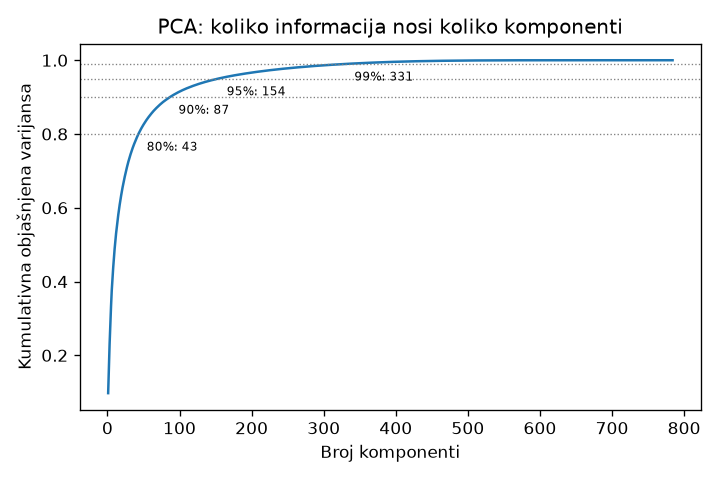

**Fashion-MNIST**

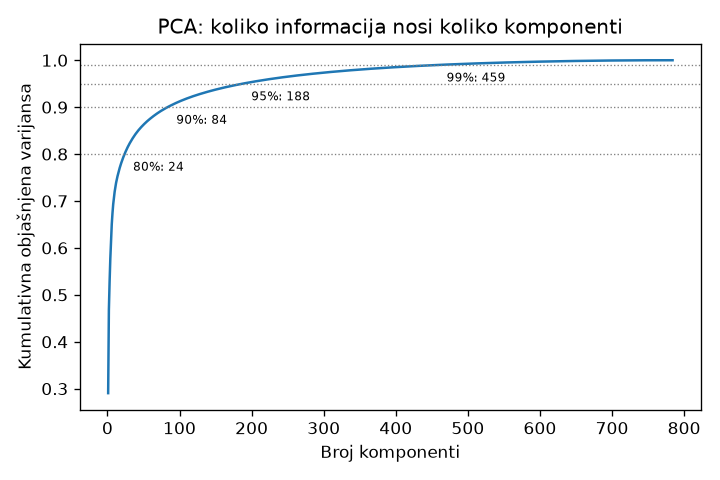

In [8]:
pragovi = pd.DataFrame({naziv: {k.replace("pca_komp_", ""): v for k, v in sazetak[s]["deo1"].items()
                                if k.startswith("pca_komp_")}
                        for s, naziv in SKUPOVI.items()})
pragovi.index.name = "objašnjena varijansa"
display(pragovi)
oba_skupa("1a_pca_varijansa.png", 520)

- Za 80% varijanse MNIST-u treba 43 komponente, a Fashion-u samo 24: kod odeće nekoliko krupnih obrazaca (silueta,
  ukupna svetlina) objašnjava mnogo. Za 95% je obrnuto (154 naspram 188), jer Fashion ima više sitnih detalja (šare,
  teksture). PCA-50 zadržava oko 83% varijanse kod MNIST-a i 86% kod Fashion-a.
- Glavne komponente kao slike i rekonstrukcije sa različitim brojem komponenti:

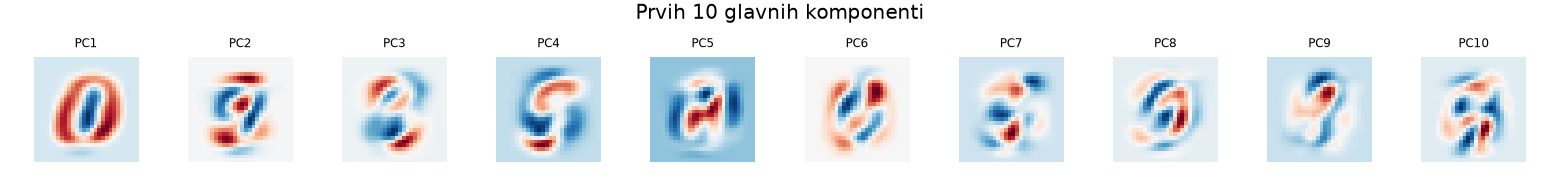

**MNIST**

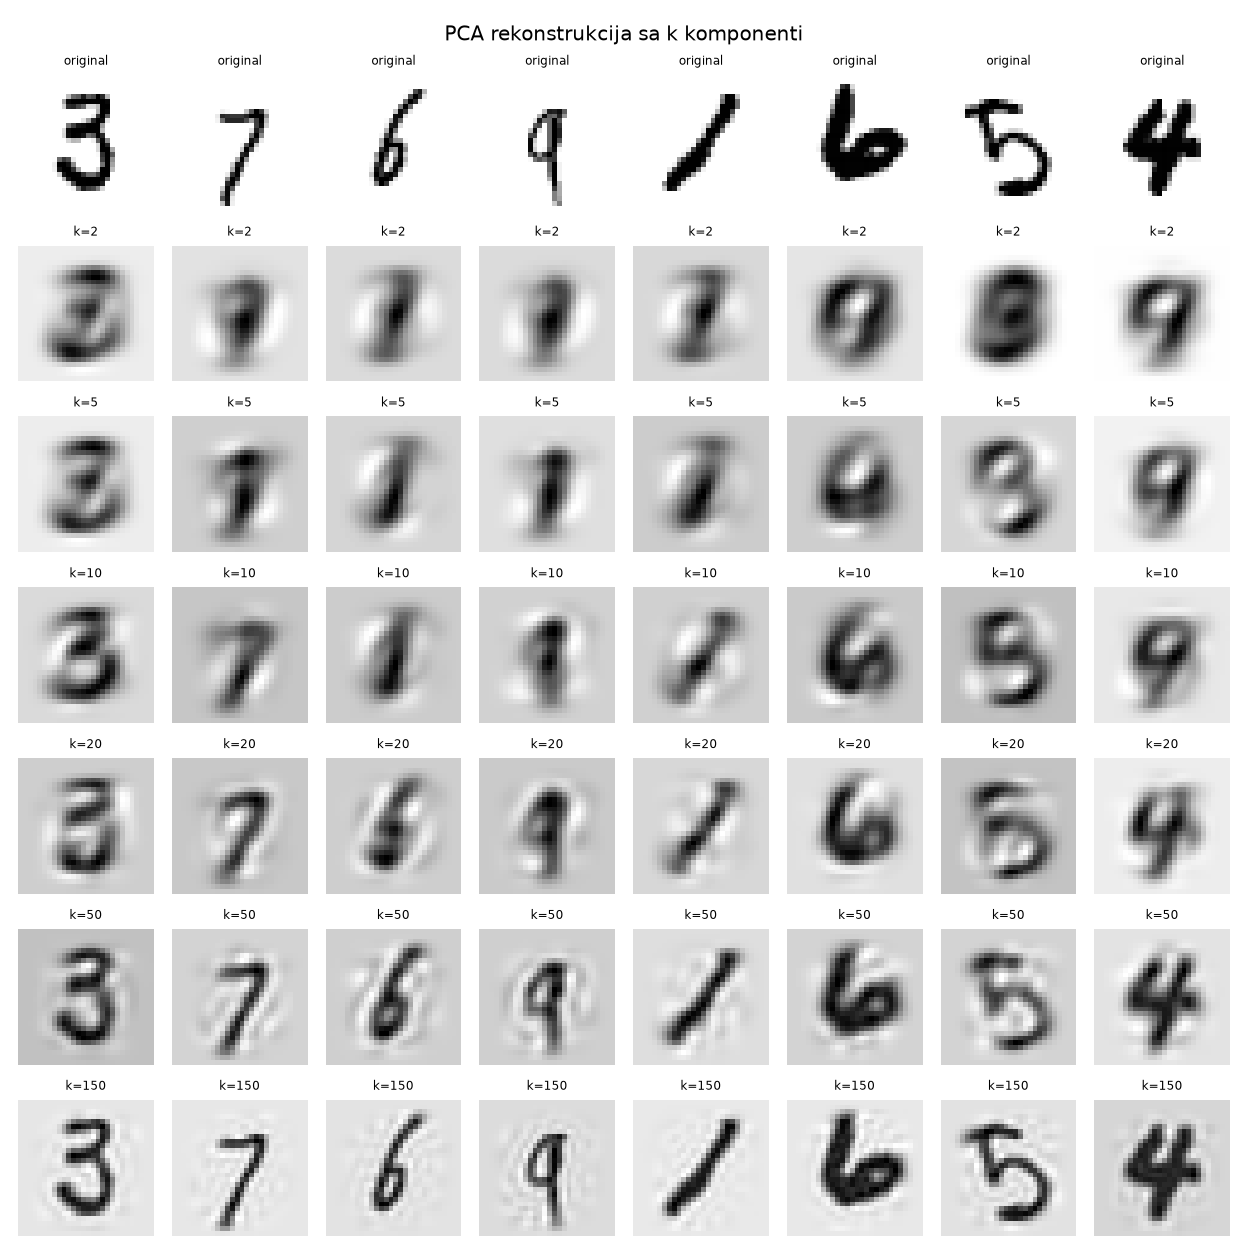

**Fashion-MNIST**

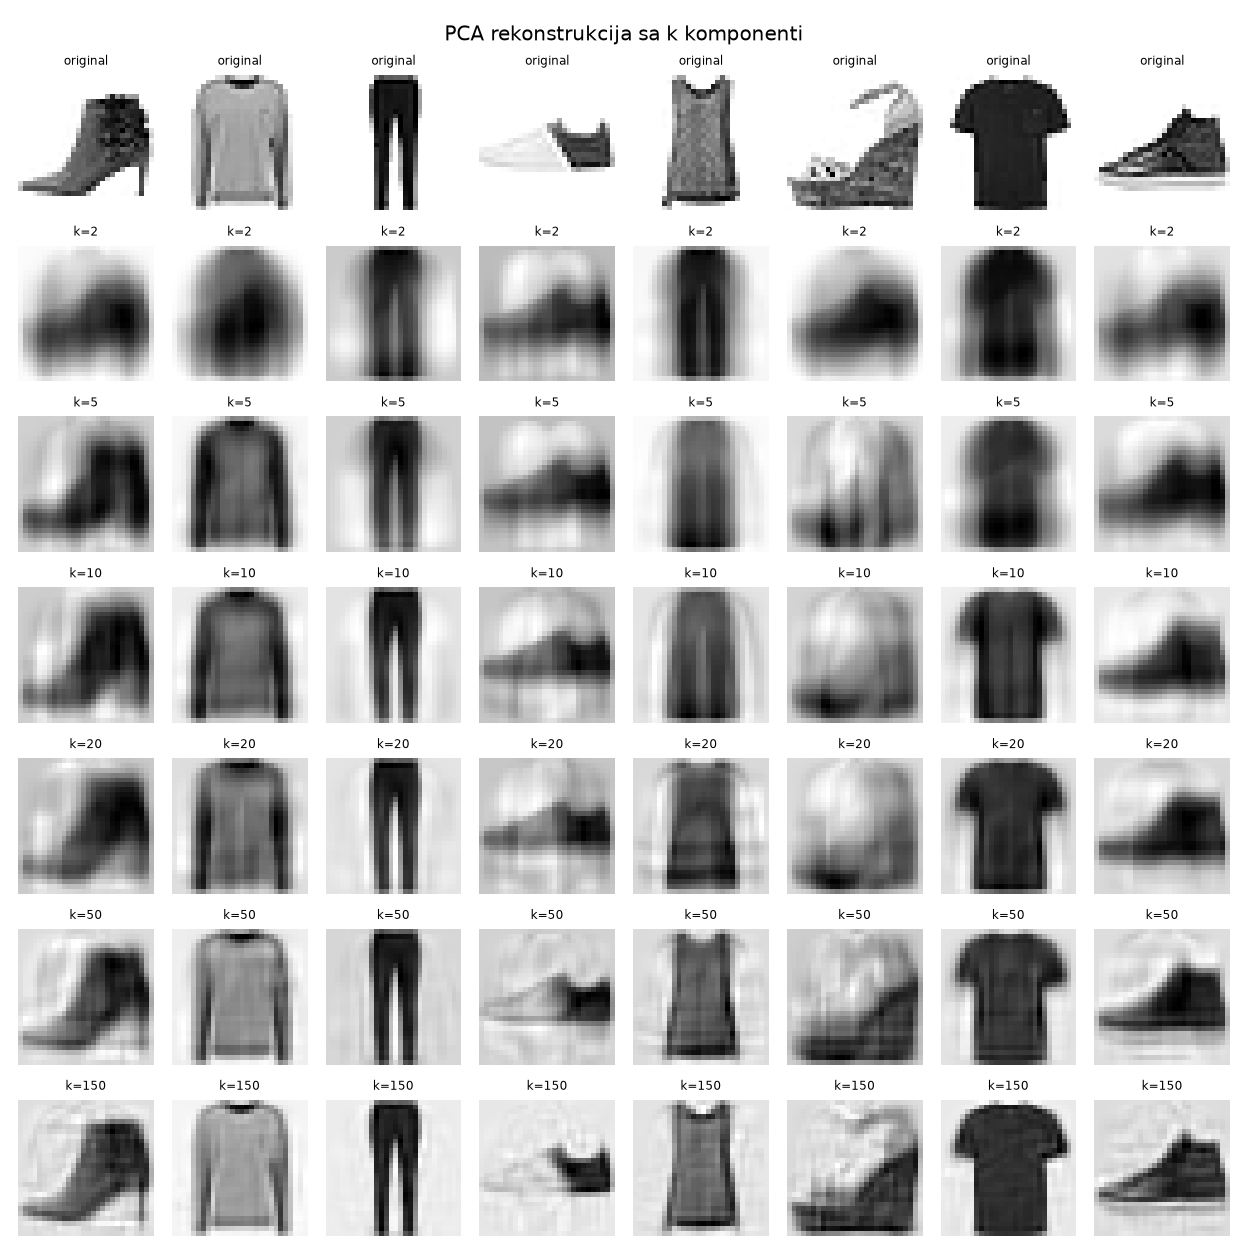

In [9]:
slika("mnist", "1b_glavne_komponente.png", 800)
oba_skupa("1c_pca_rekonstrukcije.png", 700)

Prve komponente opisuju krupne razlike („koliko mastila je u sredini", „uspravna crta ili krug", nagib), a kasnije sve
sitnije detalje. Sa 50 komponenti cifra i odevni predmet se jasno prepoznaju, samo su malo mutniji.

### 2.2 t-SNE

#### Šta je

**Ideja:** napravi 2D mapu u kojoj **bliski susedi ostaju bliski**. Velika rastojanja se ne čuvaju, jer se 50 dimenzija
ne može verno spljoštiti u 2. Algoritam (van der Maaten i Hinton, 2008) ima tri koraka:

1. susedstva u originalnom prostoru opiše **verovatnoćama P** (Gausovo zvono, širina zavisi od perplexity-ja);
2. susedstva na 2D mapi opiše **verovatnoćama Q** (Studentova t-raspodela);
3. pomera 2D tačke dok Q ne postane što sličnije P (minimizacija **KL divergencije**).

#### Korak 1: verovatnoće suseda, σ i perplexity

Za sliku $i$ verovatnoća da je slika $j$ njen sused:

$$p_{j|i} = \frac{\exp\left(-d_{ij}^2 / 2\sigma_i^2\right)}{\sum_{k \neq i} \exp\left(-d_{ik}^2 / 2\sigma_i^2\right)}$$

- Brojilac je **Gausovo zvono**: bliske slike dobijaju veliku verovatnoću, daleke praktično nulu. Imenilac služi samo
  da verovatnoće za sliku $i$ saberu 1.
- **σ (sigma)** je širina zvona, odnosno **„domet vida"** slike: mala σ znači da slika gleda samo najbliže komšije,
  velika da gleda i dalje.

Primer: slika ima 4 druge slike na rastojanjima 1, 2, 3 i 5.

| rastojanje | σ = 1 (usko zvono) | σ = 3 (široko zvono) |
|---|---|---|
| 1 | 0.81 | 0.36 |
| 2 | 0.18 | 0.31 |
| 3 | 0.01 | 0.23 |
| 5 | ≈ 0 | 0.10 |
| **efektivno suseda (perplexity)** | **≈ 1.7** | **≈ 3.7** |

**Perplexity** je efektivni broj suseda:

$$\text{Perplexity} = 2^{H(P_i)}, \qquad H(P_i) = -\sum_j p_{j|i} \log_2 p_{j|i}$$

$H$ je **entropija** (u bitima): koliko pitanja sa odgovorom da/ne u proseku treba da se pogodi izabrani sused, a
$2^H$ to pretvara u **broj jednako verovatnih mogućnosti**. Novčić ima $H = 1$ bit, pa je $2^1 = 2$; pošteni izbor
između 30 suseda ima $H = \log_2 30 \approx 4.9$ bita, pa je $2^{4.9} \approx 30$; ako je jedan sused skoro siguran,
$H \approx 0$, pa je $2^0 = 1$.

**Zašto svaka slika ima svoju σ:** u gustoj oblasti (obične jedinice) mnogo sličnih slika je vrlo blizu, a u retkoj
(neobično napisane cifre) najbliže slike su daleko. Sa istom σ za sve, slika u gustoj oblasti bi imala stotine
„suseda", a slika u retkoj nijednog. Zato mi zadajemo perplexity (u projektu **30**), a t-SNE za svaku sliku
**binarnom pretragom** traži σ tako da perplexity bude tačno 30: ako je veći, σ se smanjuje, ako je manji, povećava.

**Demonstracija:** prava raspodela $p_{j|i}$ za jednu sliku iz uzorka, sa σ nađenom binarnom pretragom, i σ za sliku
iz guste i iz retke oblasti:

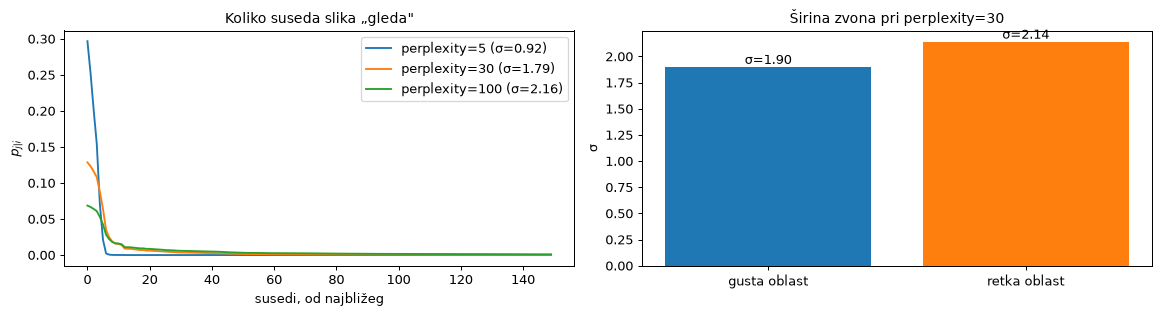

In [10]:
X50 = PCA(50, random_state=0).fit_transform(X)


def p_uslovno(d2, perp):
    # binarna pretraga za beta = 1 / (2 sigma^2) tako da 2^H = perp
    beta, lo, hi = 1.0, 0.0, np.inf
    for _ in range(200):
        p = np.exp(-(d2 - d2.min()) * beta); p /= p.sum()
        H = -(p * np.log2(p + 1e-300)).sum()
        if abs(2 ** H - perp) < 1e-3:
            break
        if 2 ** H > perp:
            lo = beta; beta = beta * 2 if np.isinf(hi) else (beta + hi) / 2
        else:
            hi = beta; beta = (beta + lo) / 2
    return p, np.sqrt(1 / (2 * beta))


X5 = X50[:500]
D2_50 = ((X5[:, None, :] - X5[None, :, :]) ** 2).sum(-1)
np.fill_diagonal(D2_50, np.inf)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for perp in (5, 30, 100):
    p, s = p_uslovno(np.delete(D2_50[0], 0), perp)
    axes[0].plot(np.sort(p)[::-1][:150], label=f"perplexity={perp} (σ={s:.2f})")
axes[0].set_xlabel("susedi, od najbližeg"); axes[0].set_ylabel("$p_{j|i}$"); axes[0].legend()
axes[0].set_title("Koliko suseda slika „gleda\"")
gustina = np.sort(D2_50, 1)[:, :10].mean(1)
for ime, j in [("gusta oblast", gustina.argmin()), ("retka oblast", gustina.argmax())]:
    _, s = p_uslovno(np.delete(D2_50[j], j), 30)
    axes[1].bar(ime, s); axes[1].text(ime, s, f"σ={s:.2f}", ha="center", va="bottom")
axes[1].set_title("Širina zvona pri perplexity=30"); axes[1].set_ylabel("σ")
plt.tight_layout(); plt.show()

Veći perplexity traži više suseda, pa je i σ veća; slika u retkoj oblasti dobija širu σ od slike u gustoj.

#### Korak 2: problem gužve i Studentova t-raspodela

Tačke na mapi dobijaju verovatnoće pomoću Studentove t-raspodele (bez σ, ista širina za sve):

$$q_{ij} = \frac{(1 + \lVert y_i - y_j \rVert^2)^{-1}}{\sum_{k \neq l} (1 + \lVert y_k - y_l \rVert^2)^{-1}}$$

**Zašto ne Gaus i u 2D: problem gužve.** U 2D najviše 3 tačke mogu biti međusobno jednako udaljene, u 10D 11, u 50D 51.
Umereno daleki susedi iz visoke dimenzije nemaju mesta u 2D, pa bi se sve zbilo u sredinu mape. t-raspodela ima
**teže repove**:

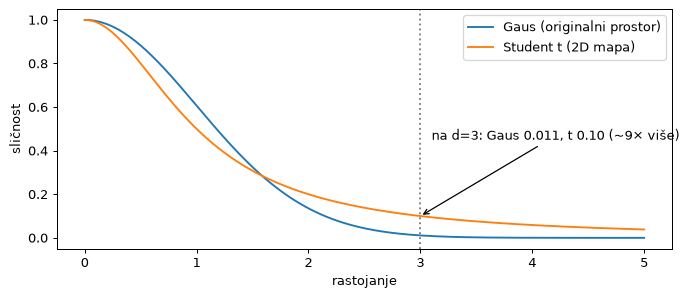

In [11]:
dd = np.linspace(0, 5, 200)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(dd, np.exp(-dd ** 2 / 2), label="Gaus (originalni prostor)")
ax.plot(dd, 1 / (1 + dd ** 2), label="Student t (2D mapa)")
ax.axvline(3, c="gray", ls=":")
ax.annotate(f"na d=3: Gaus {np.exp(-4.5):.3f}, t {1 / 10:.2f} (~9× više)", (3, 0.1), (3.1, 0.45),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("rastojanje"); ax.set_ylabel("sličnost"); ax.legend()
plt.tight_layout(); plt.show()

Da bi umereno daleki par dobio isto malu sličnost, t-raspodela ga mora postaviti **mnogo dalje**. Bliski susedi ostaju
blizu, a grupe se razmaknu. Zato t-SNE mape imaju jasna „ostrvca", i ta razdvojenost je delom **namerno pojačana**.

#### Korak 3: KL divergencija i pomeranje tačaka

$$KL(P \| Q) = \sum_{i \neq j} p_{ij} \log \frac{p_{ij}}{q_{ij}}
\qquad\qquad
\frac{\partial KL}{\partial y_i} = 4 \sum_j (p_{ij} - q_{ij}) \frac{y_i - y_j}{1 + \lVert y_i - y_j \rVert^2}$$

| Deo | Uloga |
|---|---|
| P (Gaus, σ) | **cilj**, računa se jednom i ne menja se |
| Studentova t-raspodela | **mera sličnosti na mapi**, daje Q |
| KL divergencija | **ocena mape**: jedan broj, 0 = savršeno |
| gradijent | **uputstvo za pomeranje** svake tačke |

KL je asimetrična, i to određuje ponašanje t-SNE-a:

| Situacija | $p_{ij}$ | $q_{ij}$ | Kazna |
|---|---|---|---|
| bili susedi, na mapi **daleko** | veliko | malo | **velika** |
| nisu bili susedi, na mapi **blizu** | malo | veliko | mala |

Gradijent se može zamisliti kao **opruge**: ako je $p_{ij} > q_{ij}$, opruga privlači par; ako je $p_{ij} < q_{ij}$,
odbija ga. Petlja: izračunaj Q → izračunaj KL i gradijent → pomeri svaku tačku malo → ponovi (oko 1000 puta). Krajnje
pozicije tačaka su t-SNE mapa.

**Primer sa 3 slike.** U originalu su A i B bliski susedi, a C je daleko: $p_{AB} = 0.8$, $p_{AC} = p_{BC} = 0.1$.

| Mapa | $q_{AB}$ | $q_{AC}$ | $q_{BC}$ | KL |
|---|---|---|---|---|
| početna: A = 0, C = 1, B = 3 (C između A i B) | 0.13 | 0.62 | 0.25 | 1.21 |
| posle pomeranja: A = 0, B = 0.5, C = 3 | 0.77 | 0.10 | 0.13 | 0.005 |

Na početku opruga A–B jako privlači (0.8 > 0.13), a A–C odbija (0.1 < 0.62). Posle nekoliko koraka mapa verno
prikazuje ko je kome sused i sile su skoro nula.

#### Optimizacija

- **Početak:** u projektu `init="pca"`, tačke kreću od prve dve PCA komponente.
- **Rano preuveličavanje:** prvih 250 iteracija svi $p_{ij}$ se množe sa 12. Privlačenje suseda je tada mnogo jače
  od odbijanja, pa se brzo postavi grubi raspored grupa; ostatak optimizacije ih razmiče i dotera.
- **Barnes-Hut:** udaljene grupe tačaka se u kvadratnom stablu računaju kao jedna tačka, pa složenost pada sa
  $O(n^2)$ na $O(n \log n)$. Radi samo za 2–3 dimenzije.

**Demonstracija:** isti uzorak posle 250 iteracija (kraj preuveličavanja) i posle 1000:

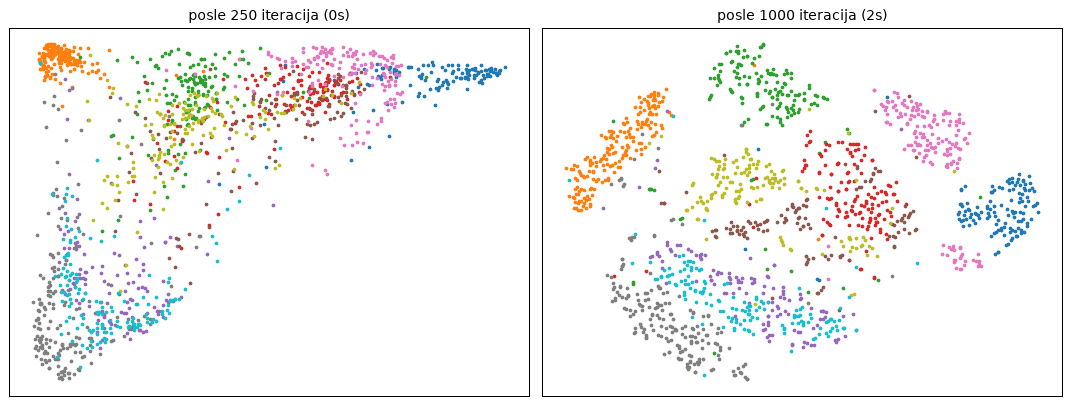

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, it in zip(axes, [250, 1000]):
    t0 = time.time()
    Z = TSNE(perplexity=30, init="pca", max_iter=it, random_state=0).fit_transform(X50[:1500])
    rasipanje(ax, Z, y[:1500], f"posle {it} iteracija ({time.time() - t0:.0f}s)")
plt.tight_layout(); plt.show()

#### Zašto koristimo t-SNE

t-SNE u projektu služi **samo za vizuelizaciju**:
1. **Da vidimo da li struktura postoji.** Ako se ni na t-SNE mapi ne vide grupe, nema smisla očekivati da će ih
   klasterovanje naći.
2. **Da pokažemo da je struktura nelinearna.** PCA u 2D daje izmešanu mrlju, a t-SNE na istim podacima jasne grupe
   (odeljak 2.6).
3. **Da objasnimo greške klasterovanja.** Kada se džemperi i kaputi pomešaju u klasterima, t-SNE mapa pokazuje da su
   izmešani i u podacima.

Zašto ga **ne** koristimo za klasterovanje: radi samo u 2–3 dimenzije (premalo za 10 klasa), nema `transform` za nove
slike, iskrivljuje gustinu i rastojanja (a K-means i GMM baš na tome rade), zavisi od seed-a i spor je (oko 90 s za
70.000 slika). Taj posao radi UMAP.

#### Kako čitati t-SNE mapu

| Šta vidiš | Znači li nešto? | Zašto |
|---|---|---|
| tačke u istoj grupi | ✅ da | upravo to t-SNE čuva |
| veličina grupe | ❌ ne | različite σ šire guste i sabijaju retke grupe |
| rastojanje između grupa | ⚠️ slabo | KL skoro ne kažnjava globalni raspored; t-raspodela razmiče grupe |
| sitne grupice | ⚠️ oprez | uz malu perplexity t-SNE može da „napravi" grupe od šuma |

**Česta zabluda:** na t-SNE mapi MNIST-a cifre izgledaju savršeno razdvojeno, ali boje su prave oznake. Algoritam boje
ne vidi; bez njih susedne grupe (npr. 4 i 9) izgledaju kao jedna veća grupa.

#### Rezultati u projektu

Ulaz je PCA-50, `perplexity=30`, `init="pca"`, 2 dimenzije. Uticaj perplexity-ja na uzorku od 3.000 slika:

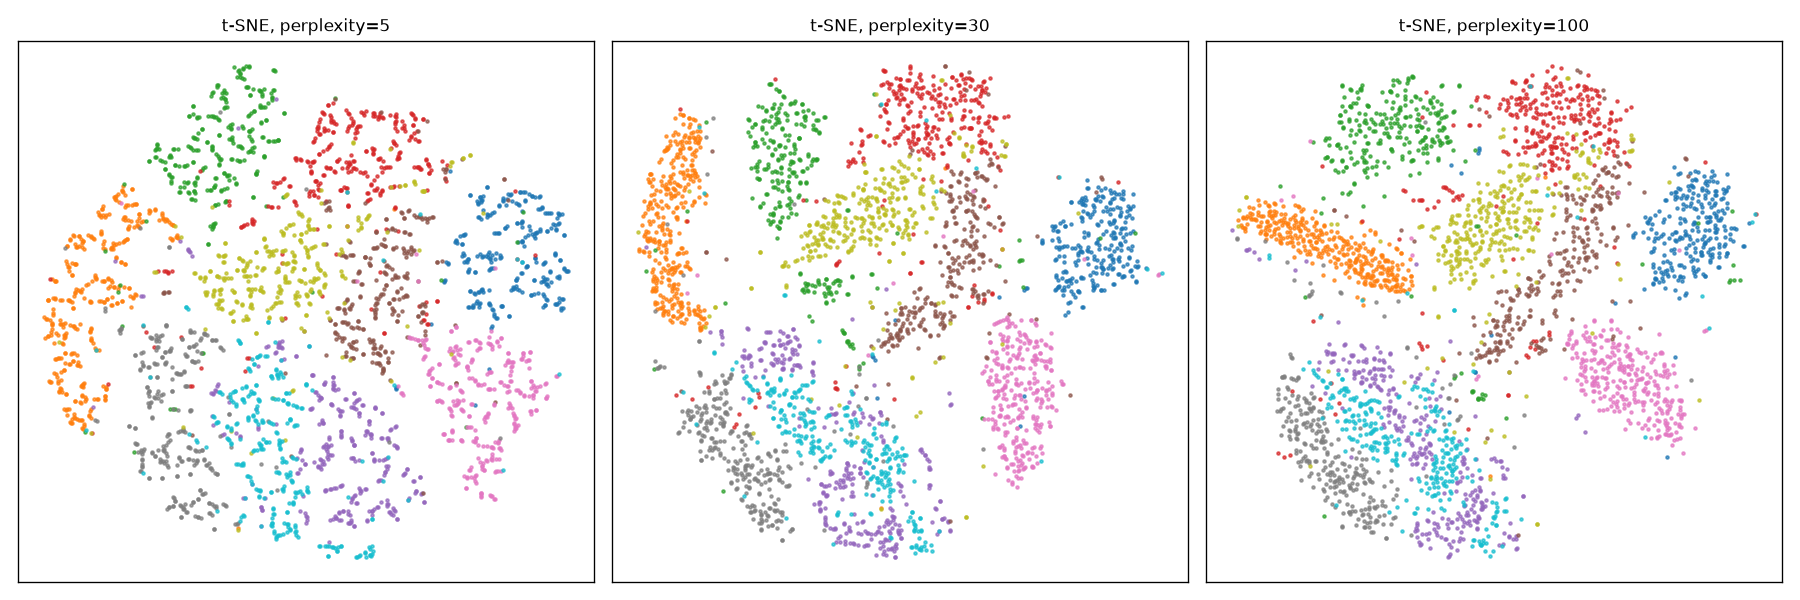

In [13]:
slika("mnist", "1g_tsne_perplexity.png", 850)

Sa perplexity 5 svaka slika gleda samo najbliže komšije: mnogo sitnih grupica i neke cifre se raspadaju. Sa 30 se
dobija 10 jasnih grupa, a sa 100 krupnije, glađe grupe i nešto bolji globalni raspored. Zato t-SNE slika **nije
„istina" o podacima**, već jedan pogled koji zavisi od parametara. Mapa na celom skupu je u odeljku 2.6.

### 2.3 UMAP

#### Šta je

**Ideja:** kao t-SNE, čuva susede, ali preko **grafa**. Brži je, bolje čuva globalnu strukturu i radi u bilo kom
broju dimenzija.

**1. Graf suseda u originalnom prostoru.** Za svaku sliku nađe se `n_neighbors` najbližih (približnom pretragom:
„susedi mojih suseda su verovatno i moji susedi"), i svaka veza dobija težinu između 0 i 1:

$$v_{j|i} = \exp\left(-\frac{d_{ij} - \rho_i}{\sigma_i}\right)$$

- $\rho_i$ je rastojanje do **najbližeg** suseda, pa najbliži sused uvek ima težinu 1: i slika u retkoj oblasti ima
  bar jednu jaku vezu;
- $\sigma_i$ se podešava tako da zbir težina bude $\log_2(k)$, sličan trik kao perplexity;
- slike van liste suseda imaju težinu 0.

Veze se spajaju u jedan graf („rasplinuta unija"): $v_{ij} = v_{j|i} + v_{i|j} - v_{j|i}\, v_{i|j}$.

**2. Težine na mapi:** $w_{ij} = \left(1 + a \lVert y_i - y_j \rVert^{2b}\right)^{-1}$. Za $a = b = 1$ to je ista
t-raspodela kao kod t-SNE-a; $a$ i $b$ se računaju iz `min_dist` (manji `min_dist` = zbijenije grupe). Za razliku od
t-SNE-a, ove težine se **ne normalizuju**: svaka veza je nezavisna verovatnoća „postoji / ne postoji".

**Demonstracija:** graf 3 i 15 najbližih suseda na 2D primeru sa dva luka:

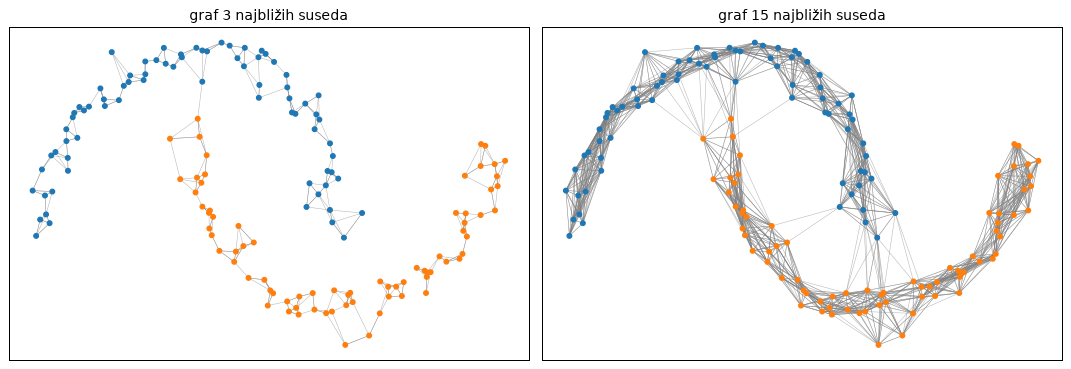

In [14]:
M, ym = make_moons(150, noise=0.07, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, k in zip(axes, [3, 15]):
    G = kneighbors_graph(M, k).tocoo()
    for a_, b_ in zip(G.row, G.col):
        ax.plot(*M[[a_, b_]].T, c="gray", lw=0.4, alpha=0.6)
    ax.scatter(M[:, 0], M[:, 1], c=[BOJE(c) for c in ym], s=14, zorder=3)
    ax.set_title(f"graf {k} najbližih suseda"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Malo suseda daje graf koji prati oblik (lukovi su odvojeni), ali je osetljiv na šum. Mnogo suseda vidi širu sliku, ali
počinje da povezuje i različite grupe.

#### Unakrsna entropija

UMAP poredi graf u originalu ($v$) i na mapi ($w$) unakrsnom entropijom:

$$CE = \sum_{i,j} \Big[\underbrace{v_{ij} \ln \frac{v_{ij}}{w_{ij}}}_{\text{privlačenje}}
\;+\; \underbrace{(1 - v_{ij}) \ln \frac{1 - v_{ij}}{1 - w_{ij}}}_{\text{odbijanje}}\Big]$$

- **Privlačenje:** važno kada su slike bile susedi ($v$ veliko); kazna je velika ako su na mapi daleko. Isti član
  postoji i u KL divergenciji kod t-SNE-a.
- **Odbijanje:** važno kada slike **nisu** bile susedi ($v$ malo); kazna je velika ako su na mapi **blizu**.
  **Ovog člana kod t-SNE-a nema.**

| Par | $v$ | $w$ | privlačenje | odbijanje | ukupno |
|---|---|---|---|---|---|
| susedi, na mapi blizu | 0.9 | 0.9 | 0 | 0 | **0** |
| susedi, na mapi daleko | 0.9 | 0.1 | 1.98 | −0.22 | **1.76**: privuci ih |
| nisu susedi, na mapi daleko | 0 | 0.1 | 0 | 0.11 | **0.11** |
| nisu susedi, na mapi blizu | 0 | 0.9 | 0 | 2.30 | **2.30**: odgurni ih |

Kod t-SNE-a bi poslednji red imao kaznu 0 (jer je $p = 0$, ceo KL član je 0).

**Minimizacija:** stohastički gradijentni spust sa uzorkovanjem. Uzme se veza iz grafa (jače veze češće), njene tačke
se privuku, pa se nekoliko nasumičnih tačaka odgurne (**negativno uzorkovanje**, jer nasumična tačka skoro sigurno
nije sused). Početni raspored je **spektralno ugrađivanje** grafa, pa povezane grupe već na početku stoje blizu.
Pošto nema normalizacije preko svih parova, UMAP ne treba Barnes-Hut stablo: otprilike je linearan u broju slika i
radi u bilo kom broju dimenzija.

#### Zašto koristimo UMAP

1. **Prostor UMAP-10 za klasterovanje.** 10 dimenzija, `n_neighbors=30`, `min_dist=0`: grupe su maksimalno zbijene i
   razmaknute, pa ih i jednostavni algoritmi lako nađu. t-SNE to ne može (samo 2D, nema `transform`).
2. **2D vizuelizacija** (`n_neighbors=15`, `min_dist=0.1`) za grafike u odeljcima 2.6 i 3.5.
3. **Osnova za N2D** (odeljak 2.5).

**Zašto je UMAP verodostojniji od t-SNE-a (kod globalne strukture):**
- član za odbijanje kažnjava i lažnu blizinu nesrodnih tačaka, pa raspored grupa ima više smisla;
- spektralni početni raspored već odražava strukturu grafa;
- nema globalne normalizacije koja iskrivljuje rastojanja između dalekih grupa;
- može da radi u 10D, gde je iskrivljenje mnogo manje nego u 2D.

**Ograda:** ni UMAP ne čuva rastojanja i veličine doslovno, a `min_dist=0` veštački zbija grupe. Deo prednosti u
globalnoj strukturi potiče od početnog rasporeda: t-SNE sa PCA inicijalizacijom (kao u projektu) čuva globalnu
strukturu mnogo bolje nego sa nasumičnom (Kobak i Linderman, 2021).

| | t-SNE | UMAP |
|---|---|---|
| osnova | verovatnoće suseda (Gaus / t) | težinski graf suseda |
| funkcija cilja | KL divergencija | unakrsna entropija (privlačenje + odbijanje) |
| dimenzije | praktično 2–3 | bilo koliko (u projektu 10) |
| nove tačke | ❌ | ✅ `transform` |
| globalna struktura | slaba | bolja |
| uloga u projektu | samo 2D prikaz | **najbolji prostor za klasterovanje** |

#### Rezultati u projektu

Uticaj parametara (`n_neighbors` × `min_dist`) na uzorku od 3.000 slika:

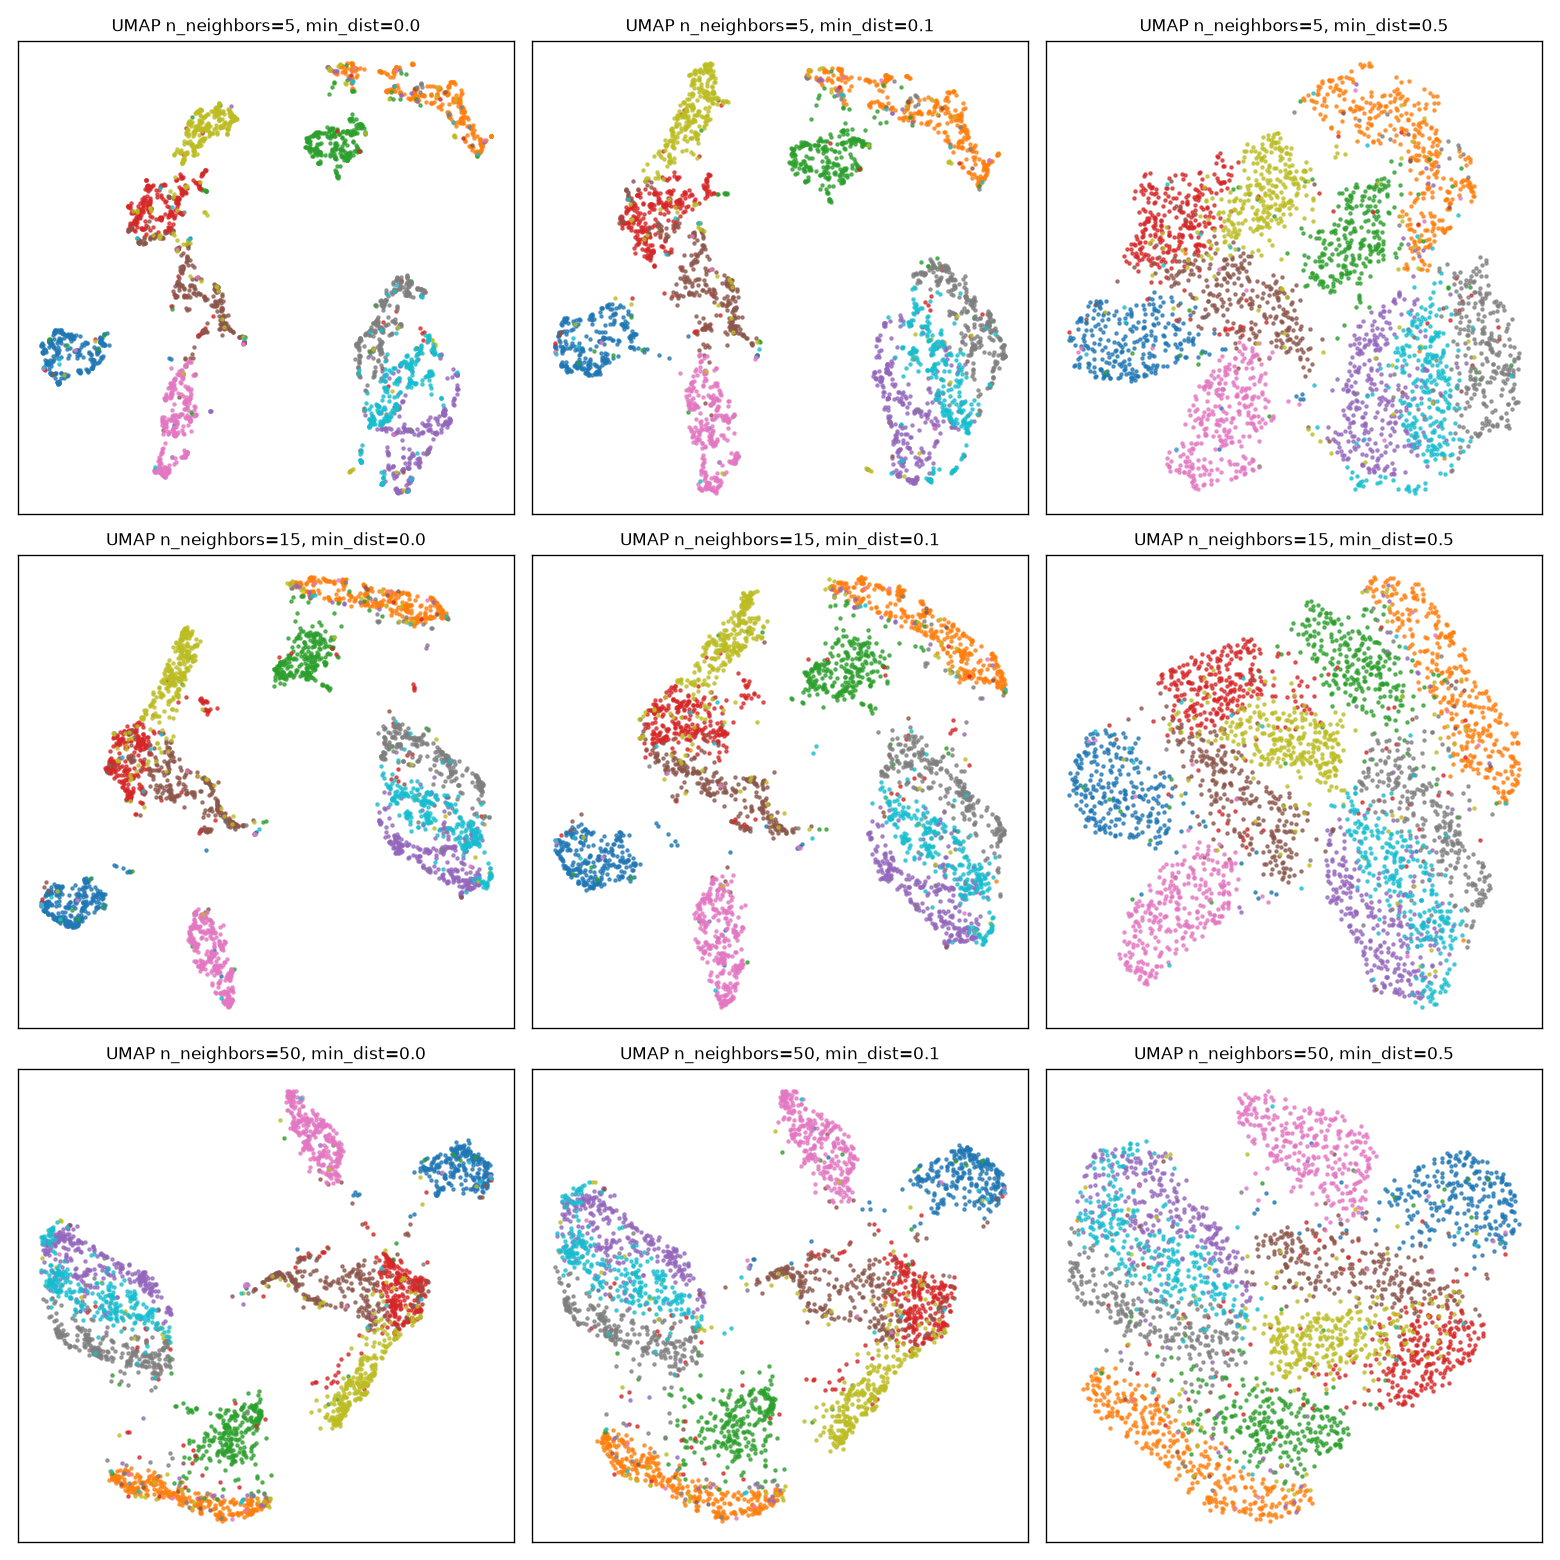

In [15]:
slika("mnist", "1h_umap_parametri.png", 800)

Manji `n_neighbors` daje više sitnih grupa, a veći spaja slične cifre u veće celine. Manji `min_dist` zbija tačke u
gušće grupe, što je pogodno za klasterovanje (zato UMAP-10 koristi `min_dist=0`). U svim varijantama UMAP drži blizu
{4, 7, 9} i {3, 5, 8}, i baš te cifre se kasnije najčešće mešaju u klasterovanju. Provereno je i `n_neighbors=15`
umesto 30 za UMAP-10: rezultat klasterovanja se nije popravio, pa je ostalo 30 (opcija `--umap_susedi`).

### 2.4 Autoenkoder

#### Šta je

**Ideja:** neuronska mreža uči da sliku **sabije u malo brojeva i iz njih je ponovo napravi**.

```
slika (784) ──► ENKODER ──► 10 brojeva ──► DEKODER ──► rekonstrukcija (784)
                            latentni prostor
```

- Kroz **usko grlo** od 10 brojeva mreža ne može da „prepiše" sliku, nego mora da nauči njenu suštinu.
- Gubitak je razlika između ulaza i izlaza, pa **oznake nisu potrebne** („tačan odgovor" je sama slika).
- Posle treninga koristi se enkoder: 10 brojeva = **naučene osobine** slike.

#### Gradivni blokovi

- **Linearni sloj:** $h = Wx + b$; svaki izlaz zavisi od svih ulaza, a $W$ i $b$ se uče.
- **ReLU:** $\max(0, a)$, nelinearnost. Bez nje bi više linearnih slojeva bilo jedno linearno preslikavanje (≈ PCA).
- **Sigmoid:** $1 / (1 + e^{-a})$ sabija izlaz u (0, 1), kao piksele; koristi se samo na poslednjem sloju.

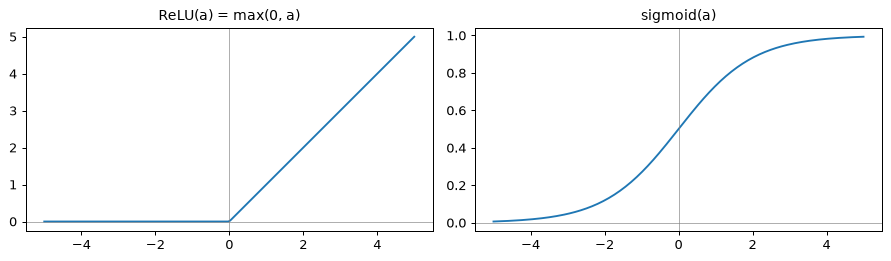

In [16]:
a = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(a, np.maximum(0, a)); axes[0].set_title("ReLU(a) = max(0, a)")
axes[1].plot(a, 1 / (1 + np.exp(-a))); axes[1].set_title("sigmoid(a)")
for ax in axes: ax.axhline(0, c="gray", lw=0.5); ax.axvline(0, c="gray", lw=0.5)
plt.tight_layout(); plt.show()

#### Konvolucija

Mali **filter** (3×3 težine) klizi preko slike i na svakom mestu računa težinski zbir 9 piksela ispod sebe:

| deo slike | filter | proizvod po elementima |
|---|---|---|
| 0.0 · 0.9 · 0.1 | −1 · 1 · 0 | 0 + 0.9 + 0 |
| 0.0 · 0.9 · 0.0 | −1 · 1 · 0 | 0 + 0.9 + 0 |
| 0.1 · 0.9 · 0.0 | −1 · 1 · 0 | −0.1 + 0.9 + 0 |

Zbir je **2.6**: jak odziv, jer filter prepoznaje uspravnu ivicu.

- **Lokalnost:** filter gleda malu okolinu, pa uči ivice, krivine i krajeve linija.
- **Deljenje težina:** isti filter se primenjuje na celoj slici, pa prepoznaje oblik bilo gde, uz malo parametara.
- **Više filtera = više kanala** (32 mape odziva u prvom sloju), a sledeći sloj slaže jednostavne obrasce u složenije.
- **Korak 2** prepolovi sliku (28 → 14), a **popuna 1** dodaje okvir nula da se obrade i ivice.
- **Transponovana konvolucija** u dekoderu radi obrnuto: udvostruči sliku (7 → 14 → 28).

**Demonstracija** sa ručno napravljenim filterima (mreža sama uči svoje):

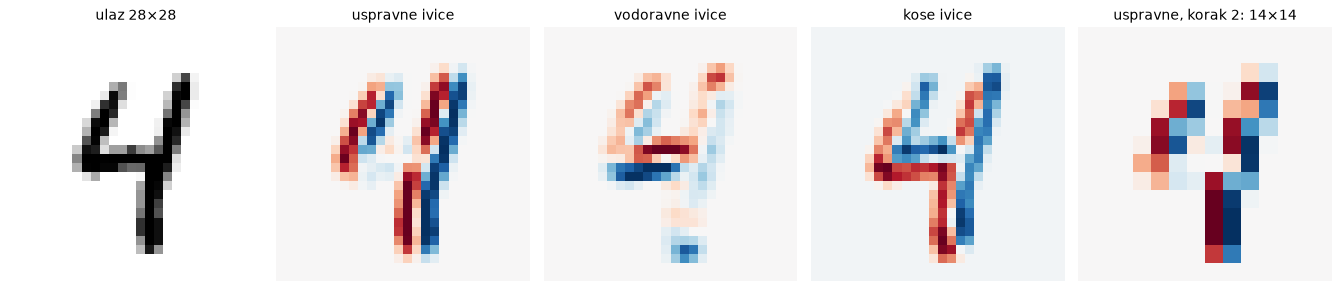

In [17]:
slika4 = X[np.where(y == 4)[0][0]].reshape(28, 28)
filteri = {"uspravne ivice": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
           "vodoravne ivice": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
           "kose ivice": np.array([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]])}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(slika4, cmap="gray_r"); axes[0].set_title("ulaz 28×28")
for ax, (ime, f) in zip(axes[1:4], filteri.items()):
    ax.imshow(correlate2d(slika4, f, mode="same"), cmap="RdBu_r"); ax.set_title(ime)
mapa = correlate2d(slika4, filteri["uspravne ivice"], mode="same")[::2, ::2]
axes[4].imshow(mapa, cmap="RdBu_r"); axes[4].set_title(f"uspravne, korak 2: {mapa.shape[0]}×{mapa.shape[1]}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

#### Arhitektura u projektu (`autoenkoder.py`)

```
ENKODER  1×28×28 → Conv(32, 3×3, korak 2)+ReLU → 32×14×14 → Conv(64, 3×3, korak 2)+ReLU → 64×7×7 → Linear → 10
DEKODER  10 → Linear+ReLU → 64×7×7 → ConvT(32)+ReLU → 32×14×14 → ConvT(1)+Sigmoid → 1×28×28
```

Prvi sloj traži jednostavne obrasce (ivice raznih pravaca), drugi ih kombinuje u složenije (luk, petlja, ukrštanje),
a linearni sloj sve sažima u 10 brojeva. Dekoder ima svoje, posebne težine. Oblici i broj parametara, izračunati iz modela:

In [18]:
m = ae.KonvAutoenkoder(10)
h, redovi = torch.zeros(1, 784), []
for deo, slojevi in [("enkoder", m.enkoder), ("dekoder", m.dekoder)]:
    for s in slojevi:
        h = s(h)
        redovi.append({"deo": deo, "sloj": s.__class__.__name__, "izlaz": "×".join(map(str, h.shape[1:])),
                       "parametara": sum(p.numel() for p in s.parameters())})
tab = pd.DataFrame(redovi)
display(tab[tab.parametara > 0].reset_index(drop=True))
print("ukupno parametara:", tab.parametara.sum(), "| PCA-10 matrica W ima", 784 * 10)

,deo,sloj,izlaz,parametara
0,enkoder,Conv2d,32×14×14,320
1,enkoder,Conv2d,64×7×7,18496
2,enkoder,Linear,10,31370
3,dekoder,Linear,3136,34496
4,dekoder,ConvTranspose2d,32×14×14,18464
5,dekoder,ConvTranspose2d,1×28×28,289


ukupno parametara: 103435 | PCA-10 matrica W ima 7840


**Konvolucioni i MLP autoenkoder.** Za MNIST i Fashion (28×28) koristi se konvolucioni. Potpuno povezani (MLP)
autoenkoder postoji samo za probni skup `digits` (8×8), jer bi konvolucioni sveo 8×8 na 2×2.

| | MLP (potpuno povezani) | Konvolucioni |
|---|---|---|
| kako gleda sliku | svaki neuron vidi sve piksele | filter vidi okolinu 3×3 i klizi |
| zna da su susedi povezani | mora da nauči | ugrađeno |
| isti oblik na drugom mestu | uči posebno | isti filter svuda |
| prvi sloj za 28×28 | ~400.000 parametara (784 → 512) | 320 parametara |

#### Trening

1. Serija od 256 slika → **prolaz unapred** → rekonstrukcije.
2. **Gubitak:** $L = \frac{1}{784}\sum_p (x_p - \hat{x}_p)^2$ (srednja kvadratna greška, MSE).
3. **Propagacija unazad:** gradijent za svaki od ~100.000 parametara 
.
4. **Adam** pomera parametre (momentum + sopstvena veličina koraka za svaki parametar), `lr = 0.001`.
5. **Epoha** = prolaz kroz sve slike, promešane. U projektu: 70.000 / 256 ≈ 274 koraka × 20 epoha ≈ 5.500 koraka.

**Demonstracija:** trening na 20.000 slika, uz praćenje gubitka i rekonstrukcija istih 8 slika:

trening: 2s, 1185 koraka


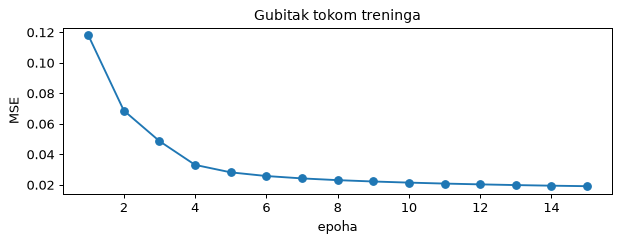

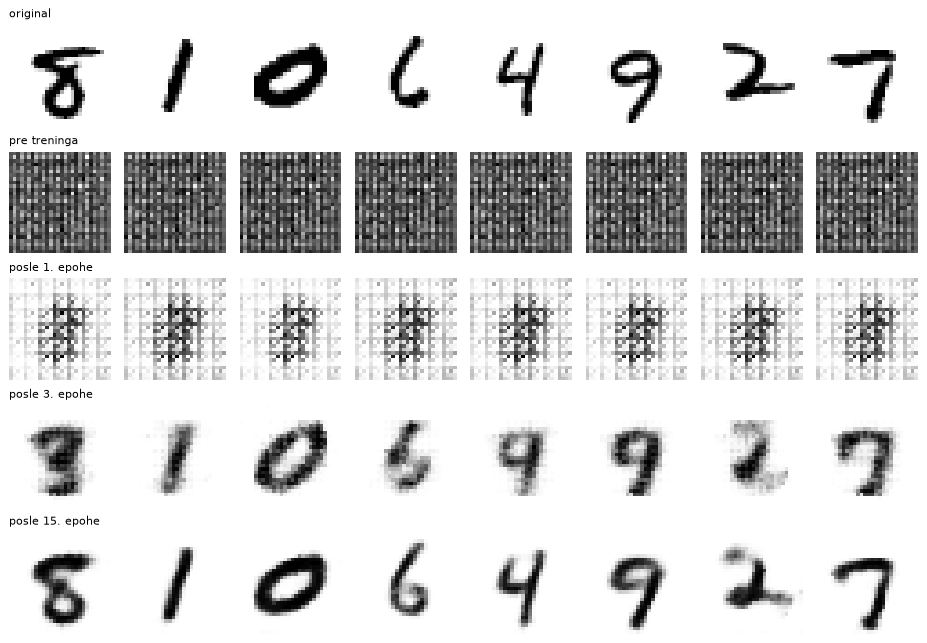

In [19]:
torch.manual_seed(0)
X_ae = torch.from_numpy(X_sve[uzorak(len(X_sve), 20000, seed=1)])
model = ae.napravi(28, 10).to(UREDJAJ)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
prati = torch.from_numpy(X[:8]).to(UREDJAJ)
gubici, snimci = [], {}
with torch.no_grad():
    snimci[0] = model(prati).cpu().numpy()
gen = torch.Generator().manual_seed(0)
t0 = time.time()
for e in range(1, 16):
    model.train(); perm = torch.randperm(len(X_ae), generator=gen); ukupno = 0.0
    for i in range(0, len(X_ae), 256):
        xb = X_ae[perm[i:i + 256]].to(UREDJAJ)
        opt.zero_grad(); gub = F.mse_loss(model(xb), xb); gub.backward(); opt.step()
        ukupno += gub.item() * len(xb)
    gubici.append(ukupno / len(X_ae))
    if e in (1, 3, 15):
        model.eval()
        with torch.no_grad():
            snimci[e] = model(prati).cpu().numpy()
model.eval(); model.uredjaj = UREDJAJ
print(f"trening: {time.time() - t0:.0f}s, {15 * int(np.ceil(len(X_ae) / 256))} koraka")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(range(1, 16), gubici, "o-"); ax.set_xlabel("epoha"); ax.set_ylabel("MSE"); ax.set_title("Gubitak tokom treninga")
plt.tight_layout(); plt.show()
mreza([X[:8]] + [snimci[e] for e in (0, 1, 3, 15)],
      ["original", "pre treninga", "posle 1. epohe", "posle 3. epohe", "posle 15. epohe"])

Pre treninga izlaz je šum, posle prve epohe mrlja u sredini, posle treće grube cifre, a posle 15 epoha skoro oštre
cifre. Mreži sa ~100.000 parametara treba dosta koraka: sa premalo podataka (npr. 3.000 slika × 15 epoha ≈ 180
koraka) rekonstruiše lošije od PCA.

#### Veza sa PCA i latentni prostor

**Linearni** autoenkoder sa jednim slojem, bez aktivacija i sa MSE gubitkom, uči isti potprostor kao PCA (enkoder
$\approx W_k^\top$, dekoder $\approx W_k$). Pravi autoenkoder dodaje **nelinearnosti** i **konvolucije**, pa može da
opiše zakrivljene obrasce i zna da je oblik isti bez obzira na položaj.

Latentnih 10 brojeva su naučene osobine, ali nema garancije da je ijedna dimenzija smislena sama za sebe, a prostor je
optimizovan za **rekonstrukciju**, ne za razdvajanje klasa. Šta latentni prostor „zna" vidi se iz interpolacije:
hodamo od latentnog vektora jedne četvorke do latentnog vektora jedne devetke.

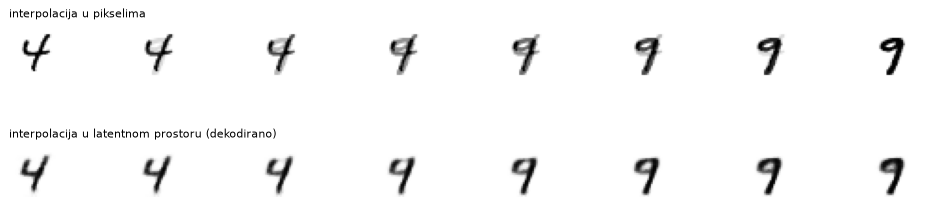

In [20]:
i4, i9 = np.where(y == 4)[0][1], np.where(y == 9)[0][1]
z4, z9 = ae.kodiraj(model, X[[i4]]), ae.kodiraj(model, X[[i9]])
tt = np.linspace(0, 1, 8)[:, None]
with torch.no_grad():
    lat = model.dekoder(torch.from_numpy(((1 - tt) * z4 + tt * z9).astype(np.float32)).to(UREDJAJ)).cpu().numpy()
mreza([(1 - tt) * X[i4] + tt * X[i9], lat],
      ["interpolacija u pikselima", "interpolacija u latentnom prostoru (dekodirano)"])

U pikselima se dve slike samo pretapaju (duh preko duha). U latentnom prostoru dekoder na svakom koraku crta
**pravu cifru** koja postepeno menja oblik, pa latentni prostor opisuje oblik, a ne pojedinačne piksele.

#### Zašto koristimo autoenkoder

1. **Nelinearna reprezentacija (prostor AE-10).** Treba da pokaže da li naučene osobine pomažu u odnosu na linearnu PCA.
2. **Osnova za N2D (AE-UMAP-10).** UMAP na osobinama autoenkodera umesto na pikselima (odeljak 2.5).
3. Latentni brojevi se **standardizuju** (prosek 0, standardna devijacija 1), jer mreža nema razloga da ih drži na
   istoj skali, a K-means i Ward bi inače gledali samo dimenziju sa najvećim brojevima.

U projektu: 20 epoha na svih 70.000 slika, GPU, oko 10 s po skupu. Ako `prostori.npz` već postoji, trening se preskače.

#### Rezultati u projektu (70.000 slika)

Pošteno poređenje sa PCA: oba metoda imaju po 10 dimenzija.

,PCA-10,Autoenkoder-10,smanjenje greške
MNIST,0.0344,0.0138,60%
Fashion-MNIST,0.0244,0.0130,47%


**MNIST**

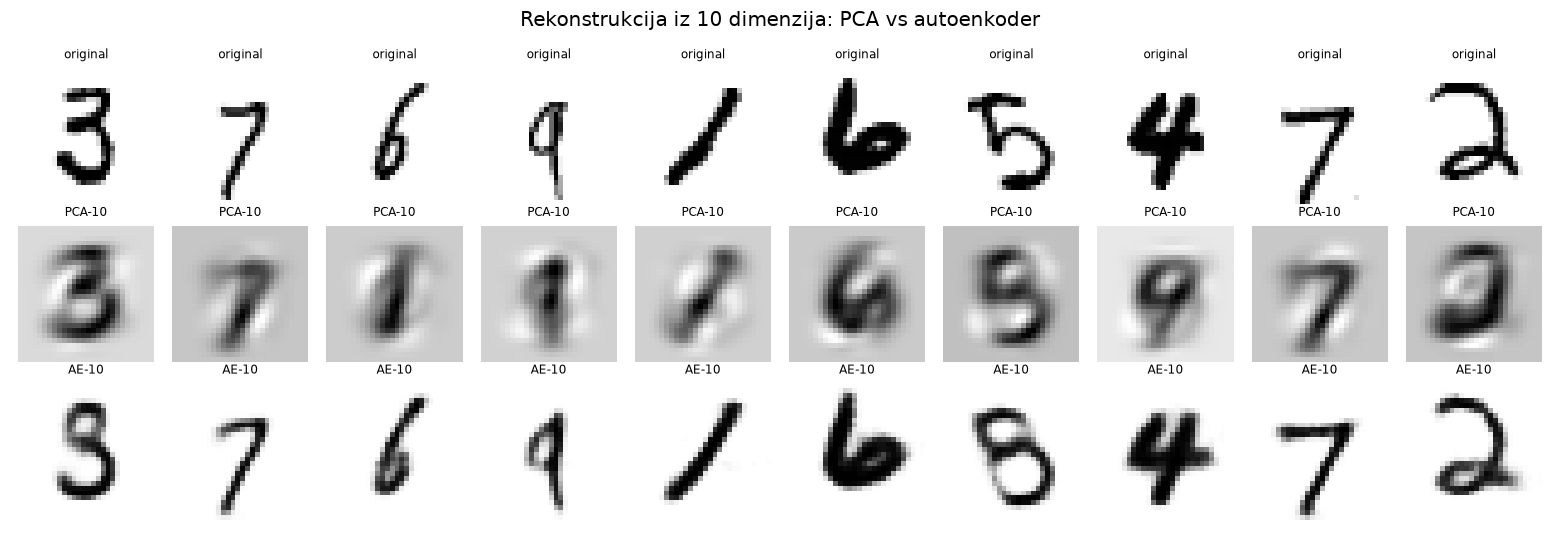

**Fashion-MNIST**

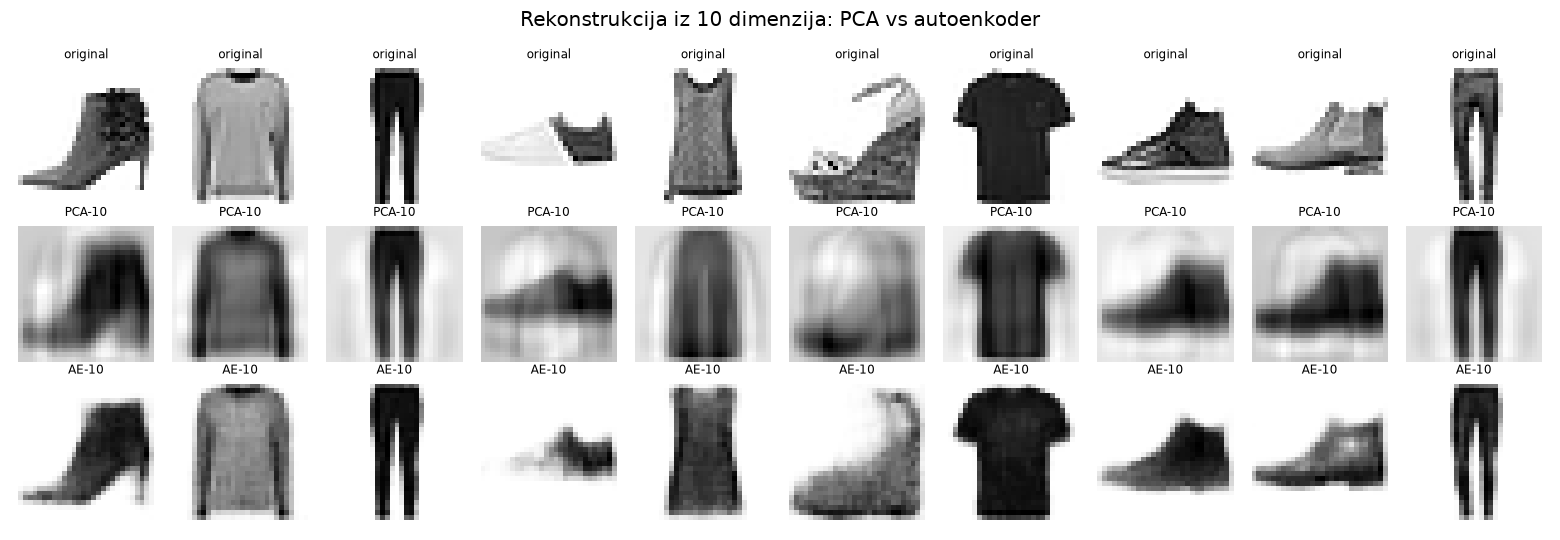

In [21]:
mse = pd.DataFrame({naziv: {"PCA-10": sazetak[s]["deo1"]["MSE_rekonstrukcije_PCA10"],
                            "Autoenkoder-10": sazetak[s]["deo1"]["MSE_rekonstrukcije_AE10"]}
                    for s, naziv in SKUPOVI.items()}).T
mse["smanjenje greške"] = (1 - mse["Autoenkoder-10"] / mse["PCA-10"]).map("{:.0%}".format)
display(mse.style.format({"PCA-10": "{:.4f}", "Autoenkoder-10": "{:.4f}"}))
oba_skupa("1e_pca_vs_ae_rekonstrukcija.png", 800)

Autoenkoder rekonstruiše znatno bolje: greška je oko 60% manja kod MNIST-a i oko 47% kod Fashion-a. PCA-10 daje mutne
„duhove", a autoenkoder skoro oštre slike. **Nelinearnost pomaže**: 10 naučenih osobina opisuje sliku bolje od 10
linearnih pravaca.

### 2.5 N2D: UMAP na osobinama autoenkodera

#### Šta je i zašto ga koristimo

N2D (McConville i sar., 2019) kombinuje dobre strane dve metode: **autoenkoder** nauči osobine slike (10 brojeva koji
opisuju oblik), a **UMAP** u tom prostoru pronađe susede i zbije grupe (UMAP 10 → 10 dimenzija, `n_neighbors=30`,
`min_dist=0`). U projektu je to prostor **AE-UMAP-10**.

UMAP na pikselima meri sličnost piksel po piksel, pa su za njega 4 i 9 vrlo slične (razlikuju se u par piksela na
vrhu). Autoenkoder može da nauči da je zatvorena „glava" devetke važna za rekonstrukciju, pa UMAP u njegovom prostoru
ima bolji materijal za razdvajanje.

**Demonstracija** na uzorku od 3.000 slika (autoenkoder iz prethodnog odeljka):

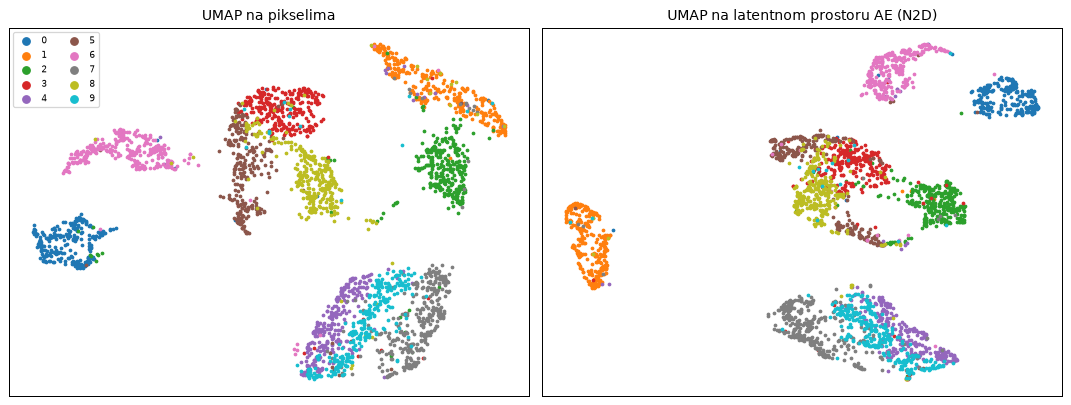

,uzorak 3.000 slika (ovaj notebook),"ceo MNIST, 70.000 slika (projekat)"
UMAP-10,0.702,0.814
AE-UMAP-10 (N2D),0.686,0.927


In [22]:
Z_ae = StandardScaler().fit_transform(ae.kodiraj(model, X))   # kao u projektu
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
rasipanje(axes[0], umap.UMAP(random_state=0).fit_transform(X), y, "UMAP na pikselima")
rasipanje(axes[1], umap.UMAP(random_state=0).fit_transform(Z_ae), y, "UMAP na latentnom prostoru AE (N2D)")
axes[0].legend(markerscale=3, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

Z_umap = umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0, random_state=0).fit_transform(X)
Z_n2d = umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0, random_state=0).fit_transform(Z_ae)
mn = klasterovanje["mnist"].query("algoritam == 'K-means'").set_index("prostor").tacnost
display(pd.DataFrame({
    "uzorak 3.000 slika (ovaj notebook)": {p_: tacnost(y, KMeans(10, n_init=10, random_state=0).fit_predict(Z_))
                                           for p_, Z_ in [("UMAP-10", Z_umap), ("AE-UMAP-10 (N2D)", Z_n2d)]},
    "ceo MNIST, 70.000 slika (projekat)": {"UMAP-10": mn["UMAP-10"], "AE-UMAP-10 (N2D)": mn["AE-UMAP-10"]},
}).style.format("{:.3f}").set_caption("Tačnost K-means-a (k = 10)"))

Na uzorku od 3.000 slika N2D **nije bolji** od običnog UMAP-10 (čak je malo slabiji), a na celom MNIST-u je ubedljivo
najbolji. Prednost se pokazuje tek kada ima dovoljno primera, da se u prostoru naučenih osobina razdvoje i slične
cifre poput 4 i 9. Kod Fashion-a N2D ne pomaže ni na celom skupu (najbolje kombinacije: 0.60 naspram 0.61 za UMAP-10),
jer su klase suštinski slične, pa ni bolje osobine ne mogu da ih razdvoje.

### 2.6 Poređenje metoda

Dvodimenzionalni prikazi celih skupova (70.000 slika). Boje su prave oznake i služe **samo za tumačenje**; metode ih
nisu videle.

**MNIST**

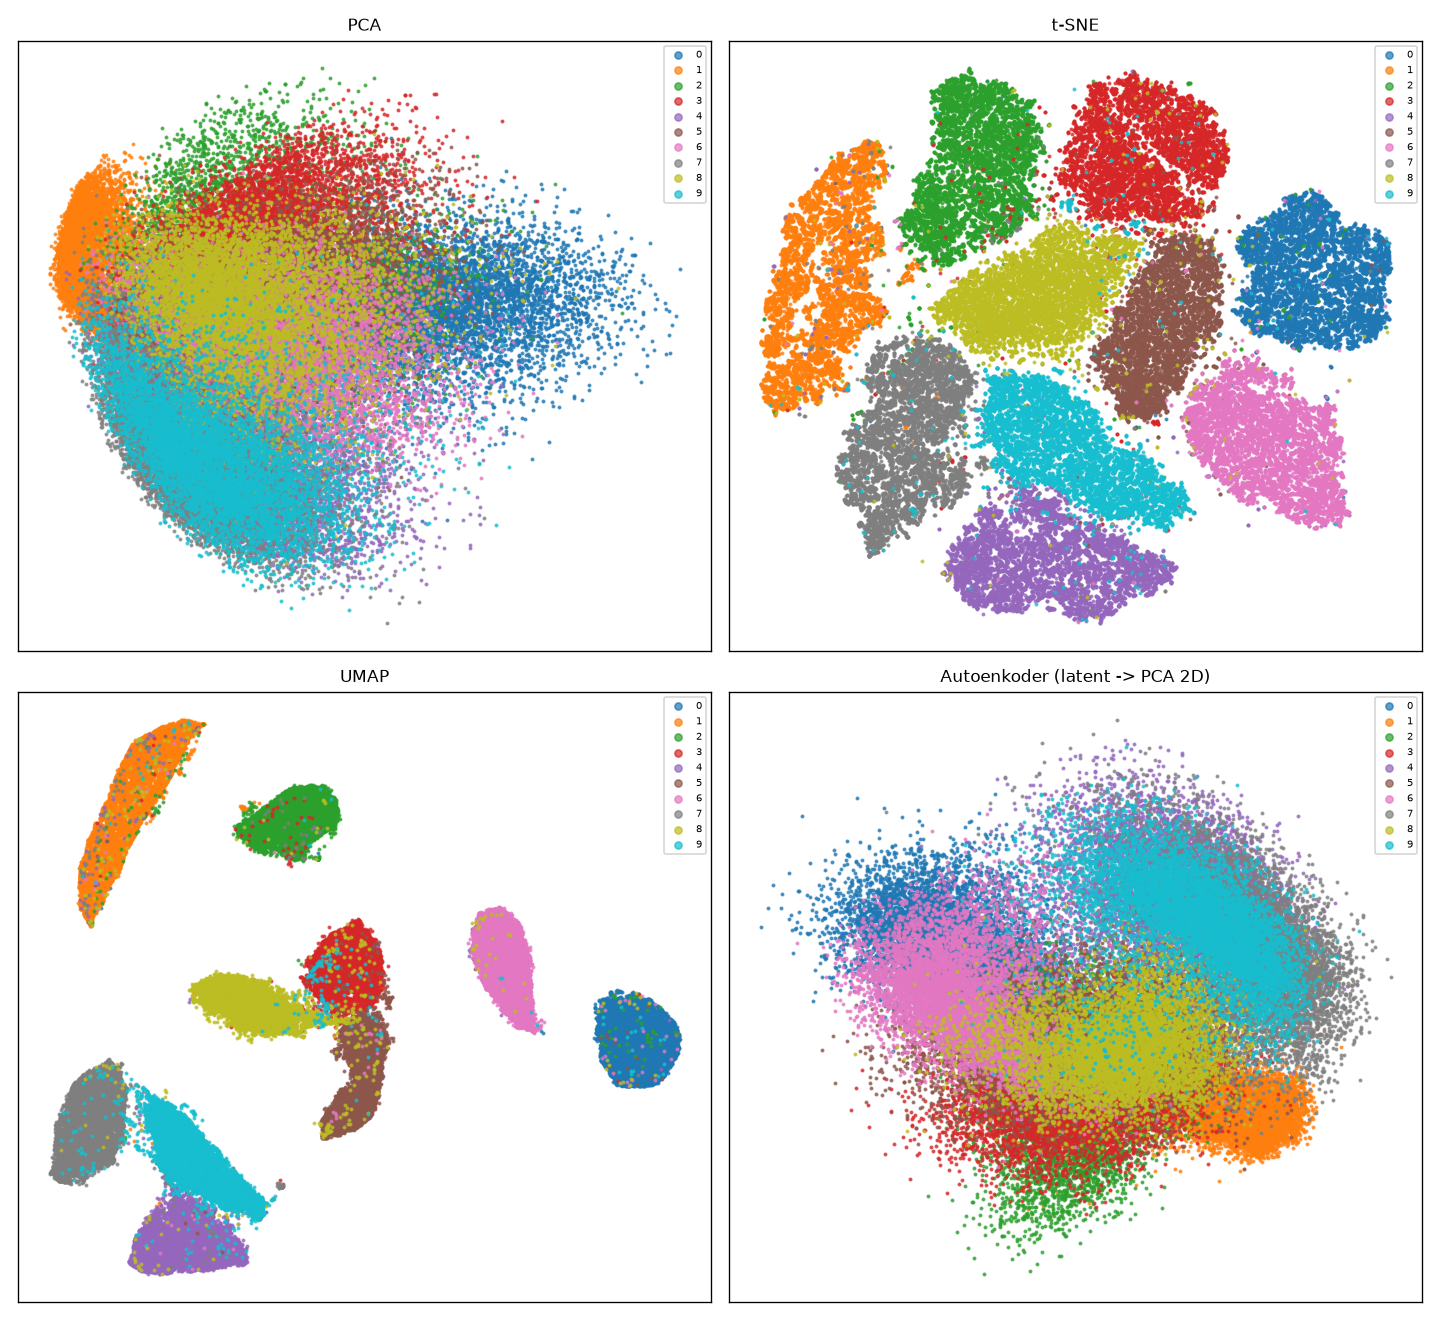

**Fashion-MNIST**

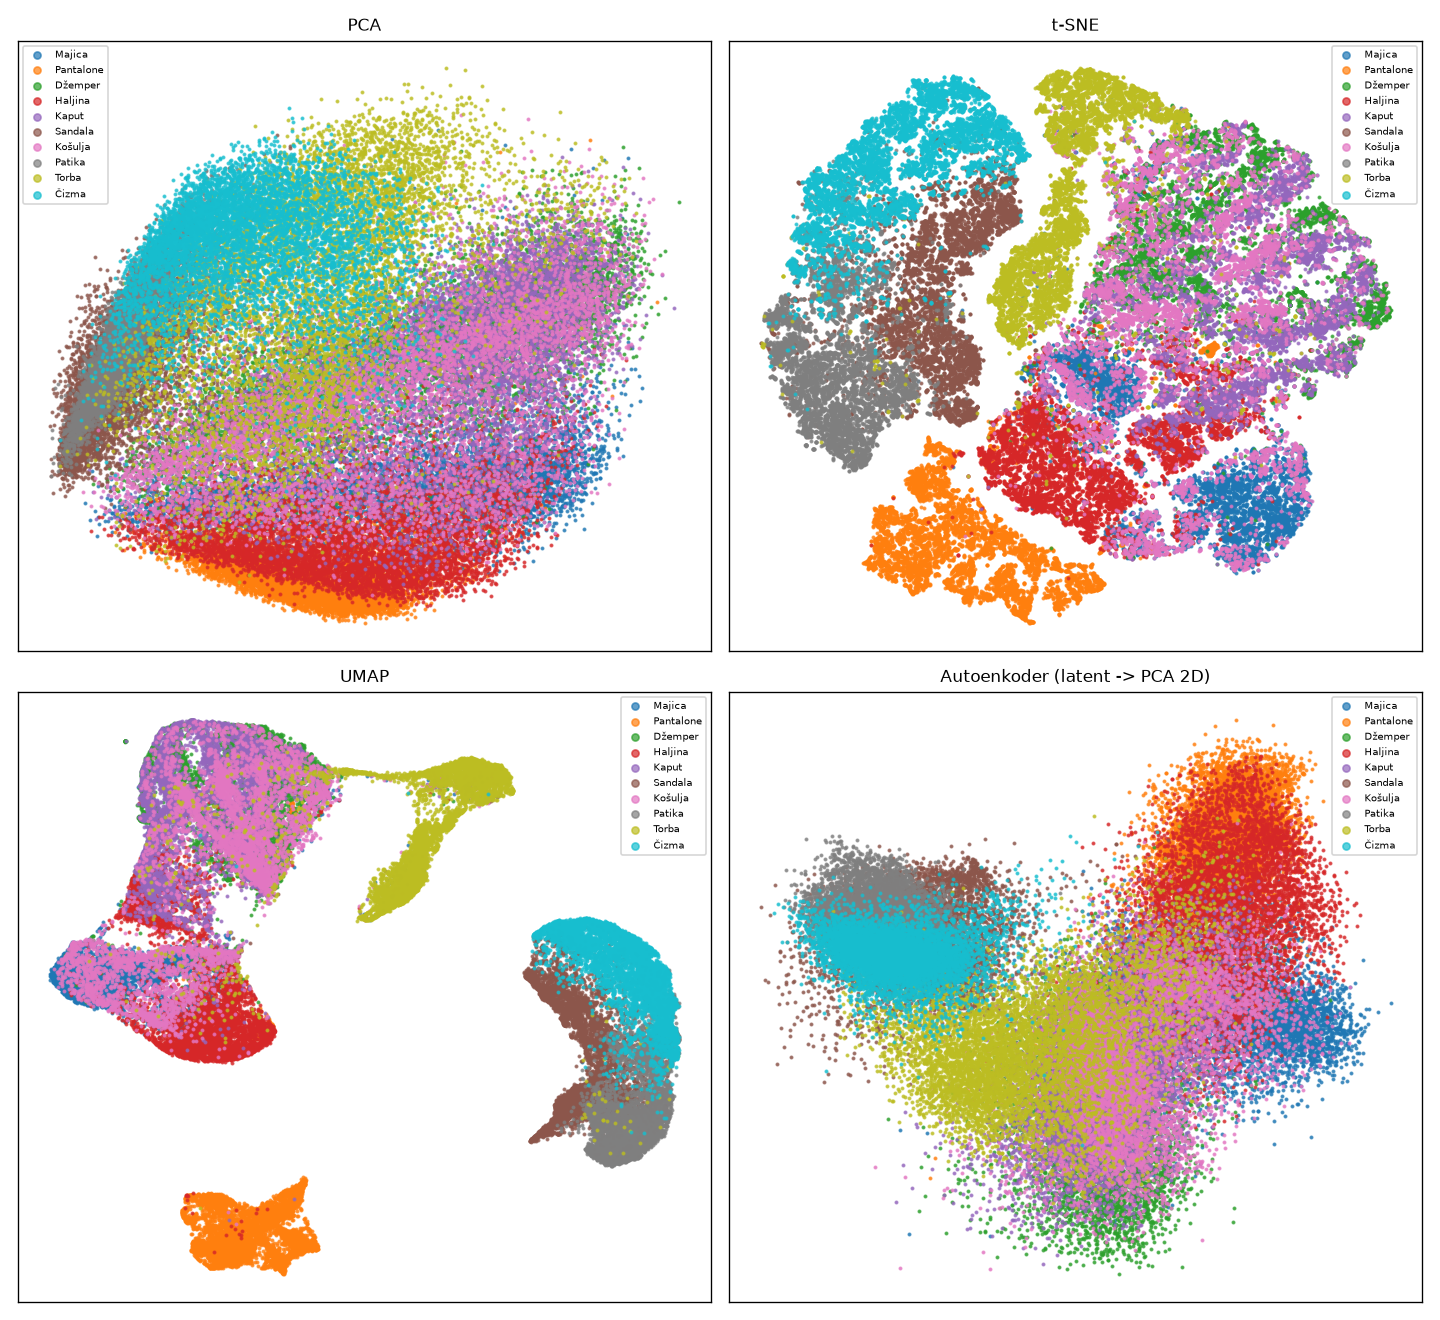

In [23]:
oba_skupa("1f_2d_poredjenje.png", 850)

- **PCA** u 2D meša skoro sve klase: dva linearna pravca nisu dovoljna.
- **t-SNE** kod MNIST-a jasno razdvaja svih 10 cifara. Struktura postoji, ali je **nelinearna**.
- **UMAP** takođe razdvaja grupe, ali drži blizu {4, 7, 9} i {3, 5, 8}, i te cifre se kasnije najčešće mešaju.
- **Autoenkoder** (10 latentnih dimenzija, projektovanih PCA-om u 2D) izgleda mutno, jer se projekcijom na dve
  dimenzije gubi deo strukture koja u 10 dimenzija postoji.
- **Fashion:** UMAP pravi oko 5 velikih grupa: pantalone, torbe, obuća (sandala, patika i čizma zajedno) i dve grupe
  gornje odeće (džemper, kaput i košulja, odnosno majica, haljina i košulja). Unutar tih grupa klase se preklapaju i u
  t-SNE prikazu. To je prvi znak da te klase neće biti razdvojive bez oznaka.

| | PCA | t-SNE | UMAP | Autoenkoder |
|---|---|---|---|---|
| linearna | da | ne | ne | ne |
| šta čuva | ukupnu varijansu | bliske susede | susede + deo globalne strukture | sve što treba za rekonstrukciju |
| ciljne dimenzije | bilo koliko | praktično 2–3 | bilo koliko | bilo koliko (arhitektura) |
| nove slike | da | ne | da | da |
| rekonstrukcija | da | ne | ne | da |
| vreme (70.000 slika) | ~1 s | ~90 s | ~60 s | ~10 s na GPU |
| treba trening | ne | ne | ne | da, i mnogo podataka |

### 2.7 Četiri prostora za klasterovanje

Klasterovanje (odeljak 3) ne radi direktno na slikama, nego na **prostorima**: matricama u kojima je svaka slika
opisana sa manje brojeva. Svi prostori kreću od iste matrice piksela $X$ (70.000 × 784), a završavaju kao matrica sa
70.000 redova i 50 ili 10 kolona. Razlikuju se po **putu** od piksela do te matrice:

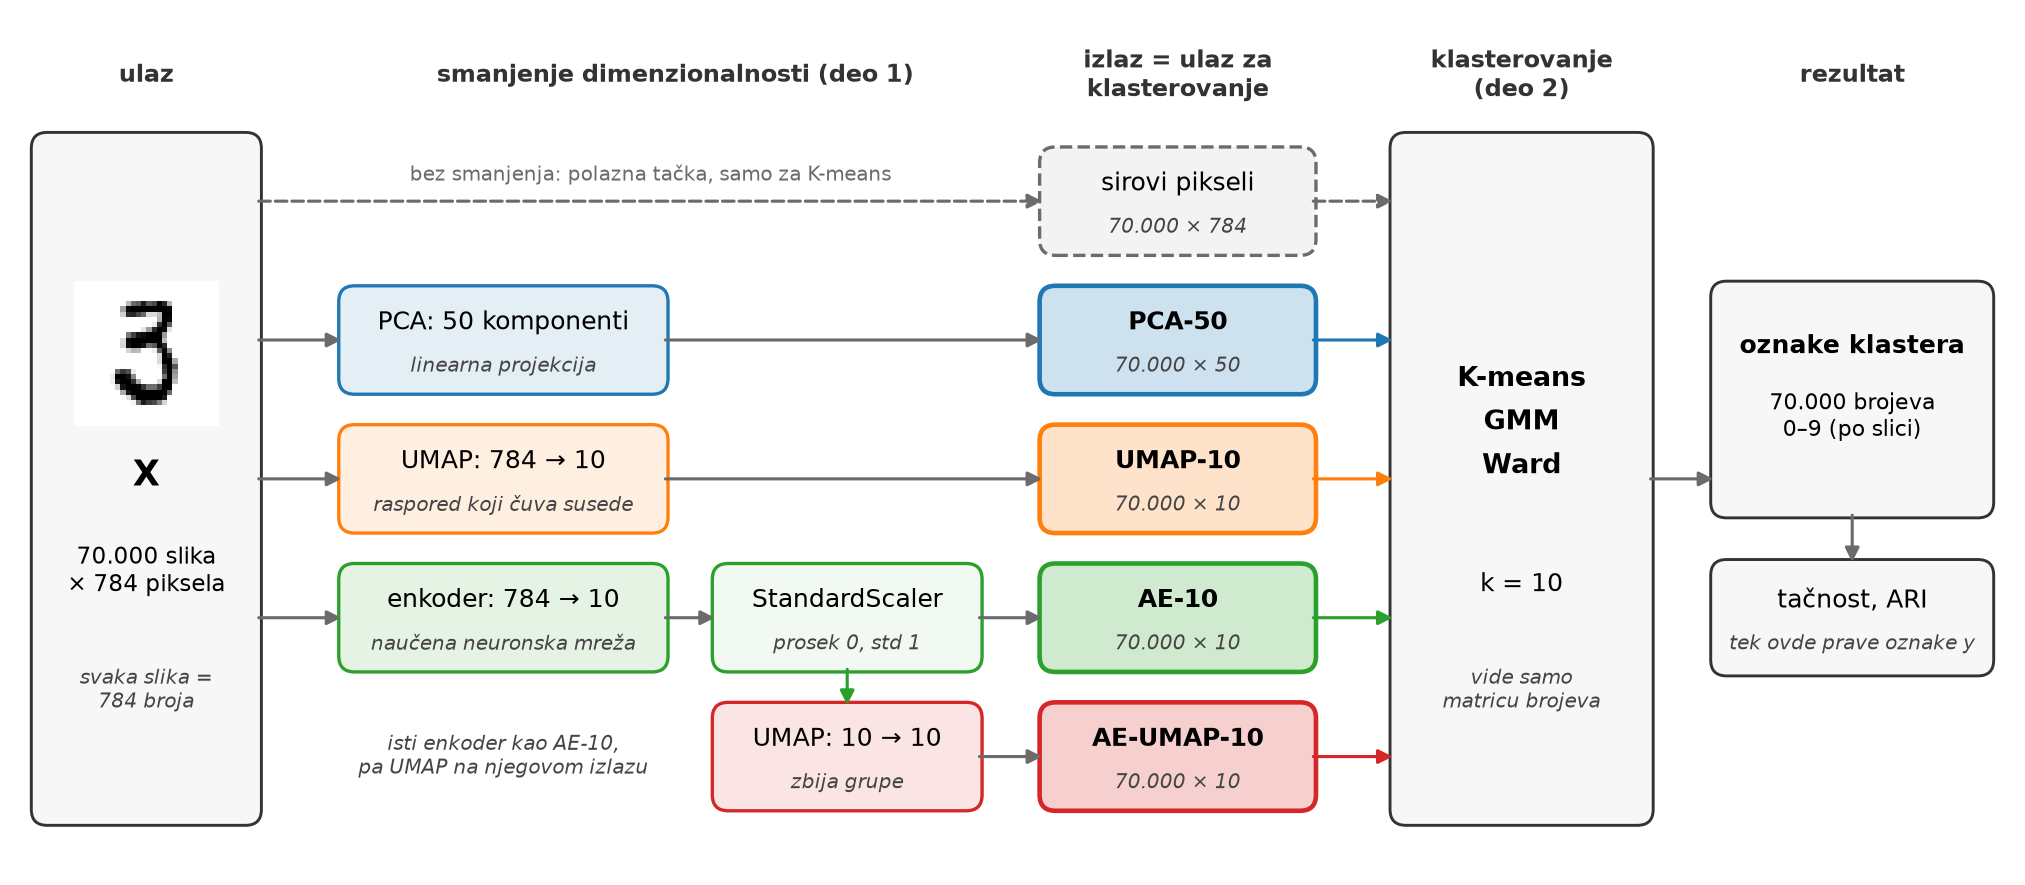

Broj u imenu prostora je **broj kolona** (dimenzija) koje dobija algoritam za klasterovanje. K-means, GMM i Ward ne
znaju odakle je matrica došla: vide samo 70.000 tačaka sa po 50 ili 10 koordinata. Svi prostori se računaju u
funkciji `izracunaj_prostore` (`deo1_dimenzionalnost.py`) i čuvaju u `rezultati/<skup>/prostori.npz`.

#### PCA-50: linearna projekcija

**Kako smanjuje dimenzionalnost:** svaku sliku projektuje na 50 pravaca sa najvećom varijansom (odeljak 2.1):

$$z = W_{50}^\top (x - \bar{x}), \qquad W_{50} \in \mathbb{R}^{784 \times 50}$$

Svaki od 50 izlaznih brojeva je **ponderisani zbir svih 784 piksela**, a težine su jedna glavna komponenta (slike
PC1–PC10 u odeljku 2.1).

- **Šta se zadržava:** 82.5% varijanse kod MNIST-a i 86.3% kod Fashion-a. Odbacuju se pravci sa malom varijansom
  (sitni detalji i šum).
- **Izlaz:** 70.000 × 50. Kolone su poređane po važnosti: prva ima najveći raspon (std 2.3 kod MNIST-a), pedeseta
  najmanji (0.4). Kolone se **ne standardizuju**: tako rastojanja ostaju približno ista kao među pikselima, a pravci
  sa malo varijanse (uglavnom šum) ne dobijaju veću težinu.
- **Osobine:** formula, bez treninga i bez nasumičnosti (~1 s); postoji put nazad u sliku, $\hat{x} = \bar{x} + W_{50} z$.
- **Šta to znači za klasterovanje:** PCA je rotacija i odbacivanje sitnih pravaca, pa su rastojanja među slikama
  skoro ista kao u pikselima. Zato K-means daje isti rezultat kao na pikselima (0.53 na MNIST-u), samo oko 15 puta brže.
- **U kodu:** `PCA(n_components=50).fit_transform(X)`

#### UMAP-10: raspored koji čuva susede

**Kako smanjuje dimenzionalnost:** UMAP ne računa izlaz formulom kao PCA, nego **traži položaje** svih 70.000 tačaka
u 10 dimenzija (odeljak 2.3):

1. za svaku sliku nađe 30 najbližih suseda u 784 dimenzije (`n_neighbors=30`) i od njih napravi težinski graf;
2. postavi tačke u 10D (spektralni početni raspored grafa);
3. pomera tačke: susede iz grafa privlači, nasumične nesusede odbija (unakrsna entropija);
4. `min_dist=0` dozvoljava susedima da se skupe skoro u istu tačku, pa nastaju **zbijene, razmaknute grupe**.

- **Šta se zadržava:** ko je kome sused. Tačna rastojanja i oblik grupa se ne čuvaju.
- **Izlaz:** 70.000 × 10. Pojedinačne ose nemaju značenje (ceo raspored se može zarotirati bez ikakve promene);
  bitno je samo ko je blizu koga.
- **Osobine:** nelinearan, zavisi od seed-a i parametara (~1 min); nema puta nazad u sliku.
- **Šta to znači za klasterovanje:** grupe su kompaktne, a to je upravo oblik koji K-means i GMM pretpostavljaju.
  K-means daje 0.81 na MNIST-u.
- **U kodu:** `umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0).fit_transform(X)`

#### AE-10: naučena funkcija (enkoder)

**Kako smanjuje dimenzionalnost:** sliku propušta kroz **enkoder**, neuronsku mrežu iz odeljka 2.4:

```
784 piksela → Conv(32, korak 2) → 32×14×14 → Conv(64, korak 2) → 64×7×7 = 3.136 → Linear → 10 brojeva
```

Svaka konvolucija prepolovi sliku po stranici i traži obrasce (ivice, lukove, petlje), a linearni sloj sve sažme u
10 brojeva.

1. **Trening:** enkoder i dekoder zajedno, 20 epoha, tako da rekonstrukcija bude što bliža originalu (MSE). Oznake
   se ne koriste.
2. **Kodiranje:** posle treninga sve slike prolaze **samo kroz enkoder**; dekoder se za klasterovanje ne koristi.
3. **Standardizacija** (`StandardScaler`): svaka od 10 kolona dobija prosek 0 i std 1. Mreža ne garantuje da su
   latentne dimenzije u istoj skali, a K-means i Ward koriste euklidsko rastojanje, pa bi dimenzija sa najvećim
   rasponom dominirala.

- **Šta se zadržava:** ono što je potrebno za rekonstrukciju. Greška rekonstrukcije je kod MNIST-a oko 60% manja nego
  za PCA-10 (0.014 naspram 0.034).
- **Izlaz:** 70.000 × 10. Pojedinačni brojevi nemaju značenje razumljivo čoveku (ne važi npr. „dimenzija 3 = nagib").
- **Osobine:** nelinearan, uči ~100.000 parametara (~10 s na GPU); dekoder daje put nazad u sliku.
- **Šta to znači za klasterovanje:** K-means daje 0.76 na MNIST-u, mnogo bolje od PCA-50, ali grupe nisu toliko
  zbijene kao posle UMAP-a (UMAP-10: 0.81).
- **U kodu:** `ae.treniraj(X, vel, latent=10, epohe=20)`, pa `StandardScaler().fit_transform(ae.kodiraj(model, X))`

#### AE-UMAP-10 (N2D): enkoder, pa UMAP

**Dva koraka:** 784 → (enkoder + standardizacija) → 10 → (UMAP) → 10. Prvi korak je isti kao za AE-10, a drugi je
isti UMAP kao za UMAP-10 (`n_neighbors=30`, `min_dist=0`), samo što na ulazu dobija AE-10 umesto piksela.

**Važno:** dimenzionalnost smanjuje samo enkoder (784 → 10). UMAP ovde ide **iz 10 u 10 dimenzija**: ne smanjuje
broj brojeva, nego **premešta tačke** tako da se susedi iz prostora naučenih osobina skupe u zbijene grupe.

- **Izlaz:** 70.000 × 10, sa istim osobinama kao UMAP-10 (ose bez značenja, bitni su susedi).
- **Šta to znači za klasterovanje:** spaja prednosti oba koraka. Enkoder daje bolji opis slike od piksela, a UMAP od
  njega pravi kompaktne grupe. Ovo je najbolji prostor na MNIST-u: K-means daje 0.93.
- **U kodu:** `umap.UMAP(n_components=10, n_neighbors=30, min_dist=0.0).fit_transform(p["AE-10"])`

#### Pregled

| | PCA-50 | UMAP-10 | AE-10 | AE-UMAP-10 |
|---|---|---|---|---|
| put od piksela | PCA | UMAP | enkoder + standardizacija | enkoder + standardizacija → UMAP |
| broj dimenzija | 784 → 50 | 784 → 10 | 784 → 10 | 784 → 10 → 10 |
| kako | linearna formula | traženje rasporeda | naučena nelinearna funkcija | funkcija, pa raspored |
| šta čuva | ukupnu varijansu | susede | sve što treba za rekonstrukciju | susede u prostoru naučenih osobina |
| kolone imaju značenje | da (glavne komponente) | ne | ne | ne |
| zavisi od seed-a | ne | da | da | da |
| put nazad u sliku | da | ne | da (dekoder) | ne |
| vreme (MNIST, 70.000 slika) | 1 s | 57 s | 11 s (GPU) | 11 s + 38 s |
| tačnost K-means-a (MNIST / Fashion) | 0.53 / 0.48 | 0.81 / 0.59 | 0.76 / 0.54 | **0.93** / 0.59 |

Za poređenje: K-means na sirovim pikselima (70.000 × 784) daje 0.53 / 0.54.

**Demonstracija:** jedna slika iz projekta (ista kao na šemi) u sva četiri prostora. Vektori se čitaju iz
`rezultati/mnist/prostori.npz` (izlaz dela 1), a oznake klastera iz `rezultati/mnist/2_klasteri.npz` (izlaz dela 2).

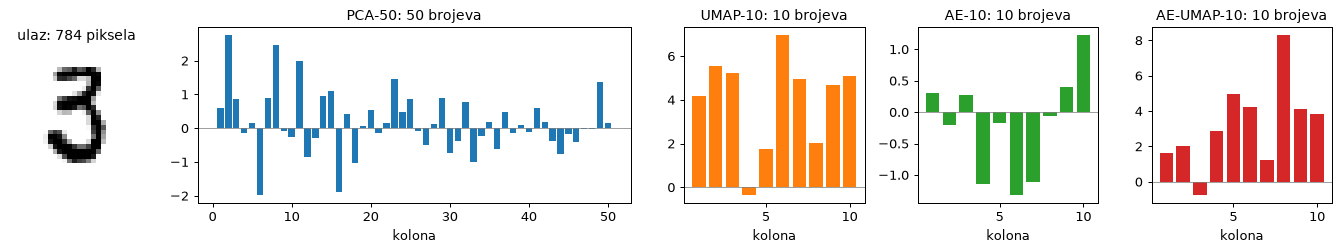

,oblik matrice,prva 4 broja ove slike,K-means klaster ove slike
PCA-50,"(70000, 50)","0.60, 2.75, 0.86, -0.15",9
UMAP-10,"(70000, 10)","4.16, 5.56, 5.22, -0.34",9
AE-10,"(70000, 10)","0.31, -0.20, 0.28, -1.14",3
AE-UMAP-10,"(70000, 10)","1.60, 2.02, -0.73, 2.90",9


In [ ]:
# ista slika kao na šemi: prva slika uzorka iz glavni.py (70.000 slika, seed 42)
p_mn = np.load(R / "mnist" / "prostori.npz")
kl_mn = np.load(R / "mnist" / "2_klasteri.npz")
red = uzorak(len(X_sve), sazetak["mnist"]["uzorak"], seed=42)
i = 0
cetiri = ["PCA-50", "UMAP-10", "AE-10", "AE-UMAP-10"]

fig, axes = plt.subplots(1, 5, figsize=(15, 2.9), gridspec_kw={"width_ratios": [0.75, 2.4, 1, 1, 1]})
axes[0].imshow(X_sve[red[i]].reshape(28, 28), cmap="gray_r"); axes[0].axis("off")
axes[0].set_title("ulaz: 784 piksela")
for k, ime in enumerate(cetiri):
    v = p_mn[ime][i]
    axes[k + 1].bar(np.arange(1, len(v) + 1), v, color=BOJE(k))
    axes[k + 1].axhline(0, color="gray", lw=0.6)
    axes[k + 1].set_title(f"{ime}: {len(v)} brojeva"); axes[k + 1].set_xlabel("kolona")
plt.tight_layout(); plt.show()

display(pd.DataFrame({
    "oblik matrice": [str(p_mn[ime].shape) for ime in cetiri],
    "prva 4 broja ove slike": [", ".join(f"{v:.2f}" for v in p_mn[ime][i, :4]) for ime in cetiri],
    "K-means klaster ove slike": [int(kl_mn[f"{ime}|K-means"][i]) for ime in cetiri],
}, index=cetiri))

Ista slika (trojka) opisana je u svakom prostoru drugim brojevima, i oni se **ne mogu porediti između prostora**:

- **PCA-50:** prve kolone su uglavnom najveće, jer su to pravci sa najvećom varijansom; udesno vrednosti opadaju.
- **UMAP-10 i AE-UMAP-10:** vrednosti su samo koordinate rasporeda koji je UMAP našao (ovde uglavnom 0–8). Same
  vrednosti ništa ne znače; bitno je koje su tačke blizu.
- **AE-10:** vrednosti su oko 0, jer je svaka kolona posle enkodera standardizovana (prosek 0, std 1).

Za klasterovanje je svaki prostor samo matrica sa 70.000 redova. K-means vraća **jedan broj po slici**: ova trojka je
u klasteru 9 u tri prostora, a u klasteru 3 u AE-10. Ti brojevi su samo imena: klaster 9 ne znači cifru 9, a to što je
u AE-10 baš klaster 3 je slučajnost. Zato se klasteri sa pravim klasama uparuju Mađarskim algoritmom (odeljak 3.4).

## 3. Klasterovanje (deo 2)

**Zadatak:** podeli slike u grupe bez znanja o tome šta su. Tri algoritma su pokrenuta u četiri prostora iz odeljka 2.7
(PCA-50, UMAP-10, AE-10, AE-UMAP-10), uz polaznu tačku: K-means direktno na sirovim pikselima.

**Svi algoritmi dobijaju k = 10.** To omogućava čisto poređenje sa 10 pravih klasa (Mađarski algoritam uparuje 10
klastera sa 10 klasa) i pošteno poređenje algoritama i prostora. To je i ograničenje: u pravom nenadgledanom zadatku
broj klasa nije poznat, a K-means, GMM i Ward ne umeju sami da ga odrede (njima je $k$ ulazni parametar).

### 3.1 K-means

#### Šta je

**Ideja:** $k$ centara; svaka tačka pripada najbližem centru.

1. Izaberi $k$ početnih centara (k-means++: međusobno razmaknuti).
2. **Dodela:** svaku tačku pridruži najbližem centru.
3. **Pomeranje:** svaki centar premesti u prosek njegovih tačaka.
4. Ponavljaj 2–3 dok se dodele ne ustale.

Minimizuje **inerciju** $\sum_i \lVert x_i - \mu_{c(i)} \rVert^2$. Svaki korak je smanjuje, pa algoritam sigurno staje,
ali može da završi u **lokalnom minimumu**; zato se pokreće 10 puta sa različitim početkom (`n_init=10`) i bira najbolje.

**+** jednostavan i brz  **−** $k$ se zadaje unapred; pretpostavlja okrugle grupe slične veličine

#### Zašto ga koristimo

Najjednostavniji i najčešće korišćen algoritam klasterovanja, brz i na 70.000 slika. Pošto ga pokrećemo u svim
prostorima i na pikselima, služi da se izmeri **uticaj prostora**: algoritam je isti, menja se samo reprezentacija.

**Demonstracija:** iteracije na 2D primeru sa 4 grupe.

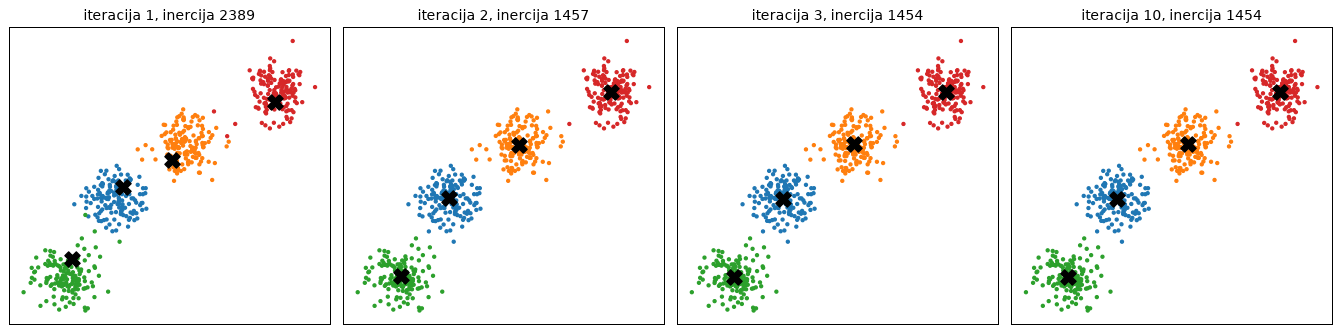

In [24]:
B, yb = make_blobs(600, centers=4, cluster_std=1.1, random_state=3)
cent = np.random.default_rng(1).choice(B, 4, replace=False)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
korak = 0
for it in range(10):
    dod = np.argmin(((B[:, None] - cent[None]) ** 2).sum(-1), axis=1)
    if it in (0, 1, 2, 9):
        ax = axes[korak]; korak += 1
        ax.scatter(B[:, 0], B[:, 1], c=[BOJE(d_) for d_ in dod], s=6)
        ax.scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=150)
        ax.set_title(f"iteracija {it + 1}, inercija {((B - cent[dod]) ** 2).sum():.0f}")
        ax.set_xticks([]); ax.set_yticks([])
    cent = np.array([B[dod == k].mean(0) for k in range(4)])
plt.tight_layout(); plt.show()

### 3.2 GMM (mešavina Gausovih raspodela)

#### Šta je

**Ideja:** podaci su nastali iz $k$ Gausovih „zvona"; svako ima centar $\mu_k$, oblik (kovarijansu) $\Sigma_k$ i težinu $\pi_k$.

**EM algoritam** ponavlja dva koraka:
- **E korak:** za svaku tačku verovatnoća da pripada svakoj komponenti, $r_{ik} \propto \pi_k \, \mathcal{N}(x_i \mid \mu_k, \Sigma_k)$
  (meka dodela);
- **M korak:** ponovo proceni $\mu_k$, $\Sigma_k$ i $\pi_k$ iz tih verovatnoća.

K-means je specijalan slučaj: tvrda dodela i okrugle, jednake grupe.

**+** izdužene i nagnute grupe, verovatnoće pripadanja  **−** sporiji; puna kovarijansa ima $d(d+1)/2$ parametara po
komponenti (d = 50: 1.275; d = 784: ~307.000)

#### Zašto ga koristimo

Grupe u stvarnim podacima (i u UMAP prostorima) često su izdužene, a ne okrugle, pa GMM proverava da li fleksibilniji
oblik pomaže. Zbog broja parametara radi samo u prostorima niske dimenzije, što je još jedan razlog za PCA-50.

**Demonstracija:** izdužene grupe na kojima K-means greši, a GMM ne.

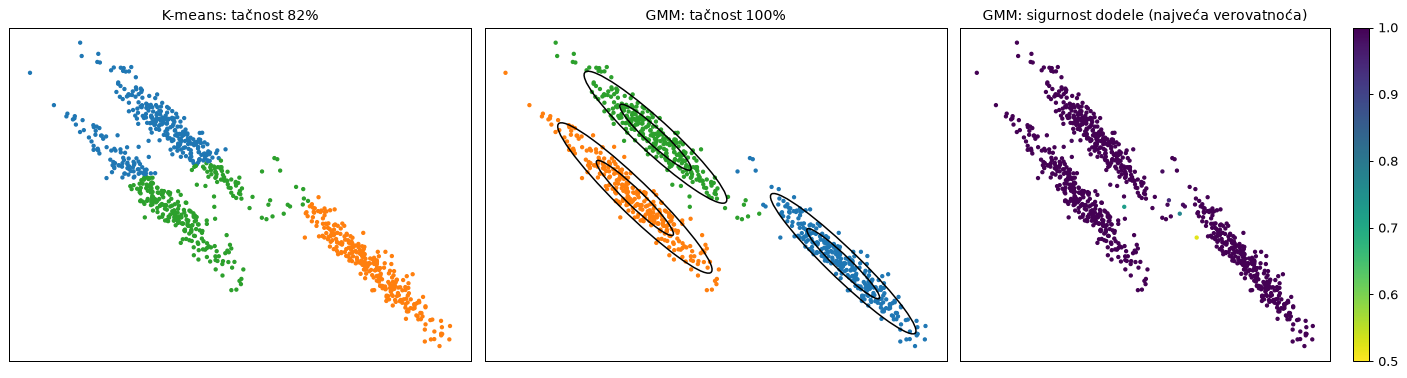

In [25]:
A, ya = make_blobs(900, centers=3, random_state=170)
A = A @ np.array([[0.6, -0.64], [-0.41, 0.85]])
km = KMeans(3, n_init=10, random_state=0).fit_predict(A)
gmm = GaussianMixture(3, covariance_type="full", random_state=0).fit(A)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, lab, ime in zip(axes, [km, gmm.predict(A)], ["K-means", "GMM"]):
    ax.scatter(A[:, 0], A[:, 1], c=[BOJE(l) for l in lab], s=6)
    ax.set_title(f"{ime}: tačnost {tacnost(ya, lab):.0%}")
for mu, cov in zip(gmm.means_, gmm.covariances_):
    vr, vk = np.linalg.eigh(cov)
    ugao = np.degrees(np.arctan2(vk[1, 1], vk[0, 1]))
    for n in (1, 2):
        axes[1].add_patch(Ellipse(mu, *(2 * n * np.sqrt(vr[::-1])), angle=ugao, fill=False, lw=1.2))
sc = axes[2].scatter(A[:, 0], A[:, 1], c=gmm.predict_proba(A).max(1), cmap="viridis_r", s=6, vmin=0.5, vmax=1)
plt.colorbar(sc, ax=axes[2]); axes[2].set_title("GMM: sigurnost dodele (najveća verovatnoća)")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 3.3 Aglomerativno klasterovanje (Ward)

#### Šta je

**Ideja:** kreni od toga da je svaka tačka svoj klaster, pa stalno spajaj **dva najbliža**.

- **Ward:** spaja par klastera čije spajanje **najmanje povećava** zbir kvadrata rastojanja unutar klastera (isti
  kriterijum kao inercija K-means-a, ali bez nasumičnog početka).
- Rezultat je **dendrogram** (stablo spajanja); presek na nekoj visini daje $k$ klastera.

**+** hijerarhija, uvek isti rezultat  **−** memorija i vreme rastu sa $n^2$

#### Zašto ga koristimo

Predstavlja drugačiji princip (hijerarhijsko spajanje odozdo naviše) i daje rezultat bez nasumičnosti. Klasičan Ward
pamti rastojanja svih parova: za 70.000 slika to je ~39 GB memorije. Zato projekat za n > 15.000 dozvoljava spajanje
samo **susednih** klastera u grafu 15 najbližih suseda; tada radi za oko 12 s. To je mala izmena algoritma, pa je
navedena među ograničenjima.

**Demonstracija:** dendrogram na 40 tačaka.

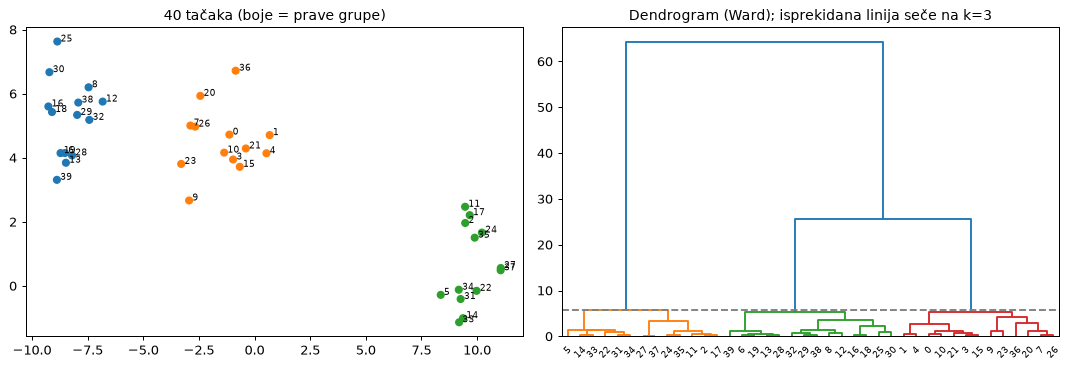

In [26]:
D, yd = make_blobs(40, centers=3, cluster_std=1.0, random_state=7)
L = linkage(D, method="ward")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(D[:, 0], D[:, 1], c=[BOJE(c) for c in yd], s=30)
for i, (a_, b_) in enumerate(D):
    axes[0].text(a_ + 0.15, b_, str(i), fontsize=7)
axes[0].set_title("40 tačaka (boje = prave grupe)")
dendrogram(L, ax=axes[1], color_threshold=L[-3, 2] + 0.01, leaf_font_size=7)
axes[1].axhline(L[-3, 2] + 0.01, ls="--", c="gray")
axes[1].set_title("Dendrogram (Ward); isprekidana linija seče na k=3")
plt.tight_layout(); plt.show()

### 3.4 Mere kvaliteta: tačnost i ARI

Klasteri nemaju imena: „klaster 3" ne znači cifru 3. Zato se oznake klastera ne mogu direktno porediti sa pravim
oznakama, i obe mere taj problem rešavaju drugačije. Primer sa 6 slika:

```
prave klase:   A  A  A  B  B  B
klasteri:      1  1  2  2  2  2
```

| | klaster 1 | klaster 2 |
|---|---|---|
| **klasa A** | 2 | 1 |
| **klasa B** | 0 | 3 |

#### Tačnost (uz Mađarski algoritam)

Svaki klaster se „imenuje" po jednoj klasi, **jedan-na-jedan**, tako da poklapanje bude najveće moguće. To je
klasičan problem dodele, koji Mađarski algoritam rešava optimalno. Tačnost = zbir poklapanja u izabranim poljima /
broj slika. U primeru: klaster 1 → A (2), klaster 2 → B (3), pa je tačnost (2 + 3) / 6 = **0.83**.

#### ARI (Adjusted Rand Index)

ARI **ne uparuje** klastere sa klasama. Za **svaki par slika** pita: da li su zajedno ili odvojeno u klasama, i da li su
zajedno ili odvojeno u klasterima. U primeru ima 15 parova:

| | u klasama zajedno | u klasama odvojeno |
|---|---|---|
| **u klasterima zajedno** | 4 ✅ | 3 ❌ |
| **u klasterima odvojeno** | 2 ❌ | 6 ✅ |

Slaže se 10 od 15 parova (Rand indeks 0.67). Pošto bi i nasumično klasterovanje imalo dosta slaganja tipa
„odvojeno–odvojeno", ARI oduzme ono što bi se očekivalo slučajno:

$$\text{ARI} = \frac{\text{stvarno} - \text{očekivano}}{\text{najveće moguće} - \text{očekivano}} = \frac{4 - 2.8}{6.5 - 2.8} \approx \mathbf{0.32}$$

(4 para zajedno i u klasi i u klasteru; očekivano slučajno $6 \cdot 7 / 15 = 2.8$, gde je 6 parova zajedno u klasama
i 7 u klasterima; najveće moguće $(6 + 7)/2 = 6.5$.) Na 70.000 slika se 2,45 milijardi parova ne prolazi jedan po
jedan, već se sve računa iz tabele klasa × klasteri.

| | Tačnost | ARI |
|---|---|---|
| šta gleda | pojedinačne slike | parove slika |
| uparivanje klaster ↔ klasa | da (Mađarski algoritam) | ne |
| nasumično klasterovanje | ≈ 0.1–0.2 | ≈ 0 |
| u primeru | 0.83 | 0.32 |

#### Zašto koristimo obe

**Tačnost** je najlakša za razumevanje („83% slika je u pravoj grupi"). **ARI** je strožiji: jedna pogrešno svrstana
slika kvari mnogo parova (u primeru jedna slika A u klasteru 2 kvari 3 para), korigovan je za slučajnost (0 =
nasumično) i ne zavisi od uparivanja. Prijavljivanje bar jedne mere tipa ARI uz tačnost je standard u radovima o
klasterovanju.

**Demonstracija:** K-means na UMAP-10 uzorka od 3.000 slika (crveno = polja koja je izabrao Mađarski algoritam).

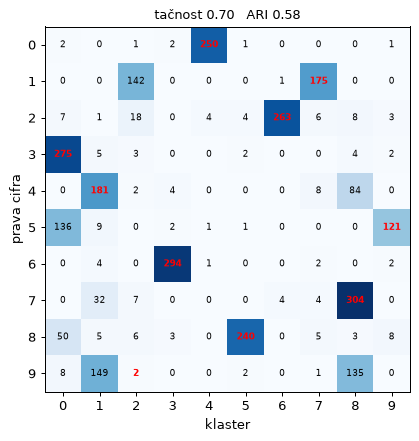

klase podeljene na više klastera: [1]
klasteri koji spajaju više klasa: {'klaster 0': [3, 5], 'klaster 1': [4, 9], 'klaster 8': [7, 9]}
klaster 2 je većinom cifra 1, ali je uparen sa klasom 9: ispisalo bi se „1 → 9", iako te slike ne liče na 9


In [27]:
kl = KMeans(10, n_init=10, random_state=0).fit_predict(Z_umap)
cm = contingency_matrix(y, kl)
r, c = linear_sum_assignment(-cm)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="red" if c[i] == j else ("white" if cm[i, j] > cm.max() / 2 else "black"),
                fontweight="bold" if c[i] == j else "normal")
ax.set_xlabel("klaster"); ax.set_ylabel("prava cifra"); ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_title(f"tačnost {cm[r, c].sum() / len(y):.2f}   ARI {adjusted_rand_score(y, kl):.2f}", fontsize=10)
plt.tight_layout(); plt.show()


def struktura(y_, kl_, prag=0.2):
    # većinska klasa svakog klastera, podeljene klase i klasteri koji spajaju više klasa
    klase, klasteri = np.unique(y_), np.unique(kl_)
    cm_ = contingency_matrix(y_, kl_)
    dominantna = {int(k): int(klase[cm_[:, j].argmax()]) for j, k in enumerate(klasteri)}
    podeljene = [int(cl) for cl in klase if list(dominantna.values()).count(cl) >= 2]
    udeo = cm_ / cm_.sum(0, keepdims=True)
    spojeni = {int(k): [int(v) for v in klase[udeo[:, j] >= prag]] for j, k in enumerate(klasteri)
               if (udeo[:, j] >= prag).sum() >= 2}
    return dominantna, podeljene, spojeni


dominantna, podeljene, spojeni = struktura(y, kl)
print("klase podeljene na više klastera:", podeljene or "nema")
print("klasteri koji spajaju više klasa:", {f"klaster {k}": v for k, v in spojeni.items()} or "nema")
for i, j in zip(r, c):
    if dominantna[j] != i:
        print(f"klaster {j} je većinom cifra {dominantna[j]}, ali je uparen sa klasom {i}: "
              f"ispisalo bi se „{dominantna[j]} → {i}\", iako te slike ne liče na {i}")

Ispis pokazuje **zamku tačnosti, artefakt uparivanja**. Kada algoritam podeli jednu klasu na dva klastera, a dve druge
spoji u jedan, višak klaster mora da dobije oznaku klase koja je ostala bez klastera. Tako nastaju „zamene" bez
stvarne sličnosti, npr. „1 → 9" kada su jedinice podeljene, a 4 i 9 spojene. ARI uparivanje ne koristi, pa je otporan
na ovaj problem. Deo 3 projekta ovakve slučajeve automatski označava (odeljak 4).

### 3.5 Rezultati klasterovanja (70.000 slika)

In [28]:
t = pd.concat({naziv: klasterovanje[s].set_index(["prostor", "algoritam"])[["tacnost", "ARI"]]
               for s, naziv in SKUPOVI.items()}, axis=1)
t.columns = [f"{mera} {skup}".replace("tacnost", "tačnost") for skup, mera in t.columns]
display(t.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0))

**MNIST**

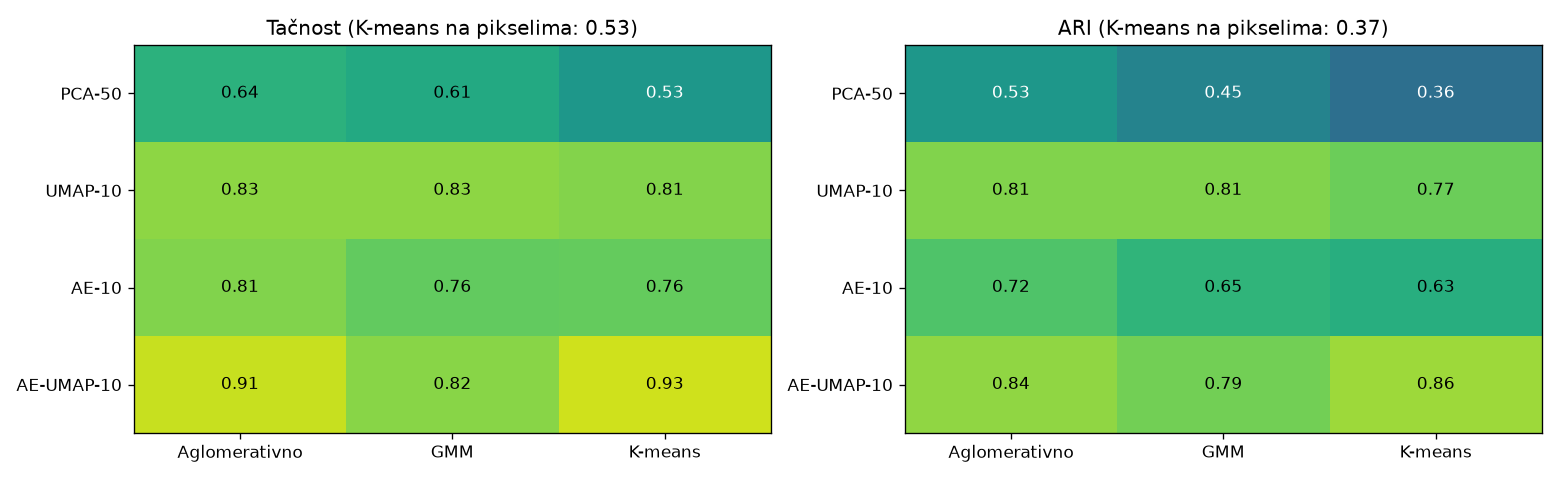

**Fashion-MNIST**

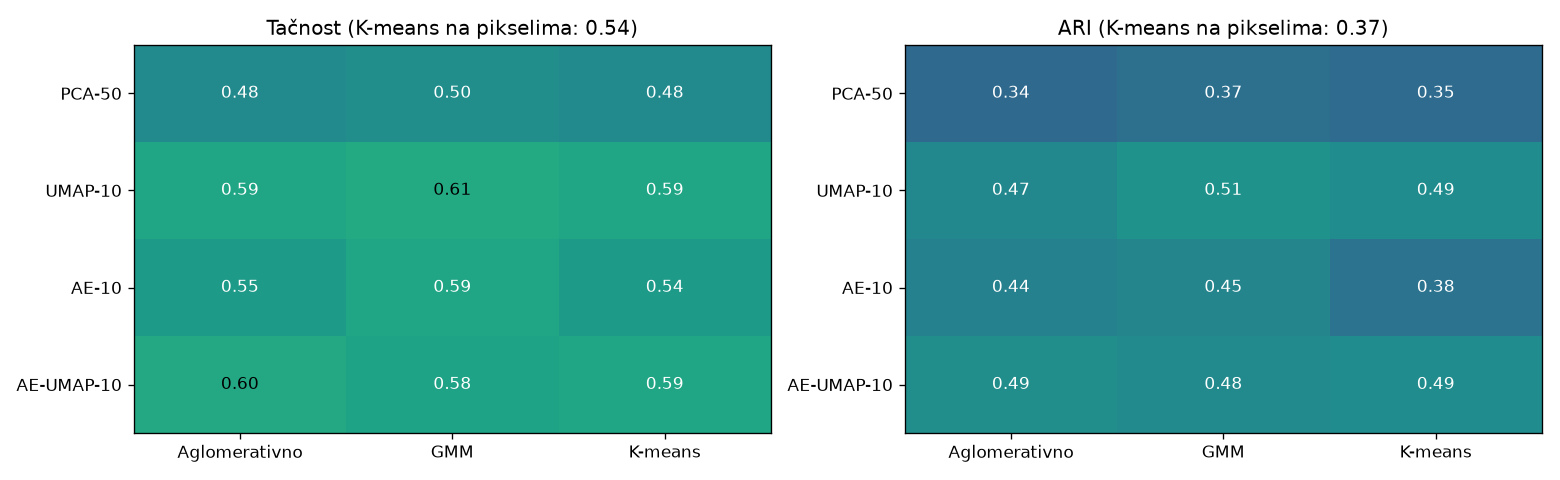

In [29]:
oba_skupa("2a_toplotna_mapa.png", 850)

Isti algoritam (K-means) u različitim prostorima:

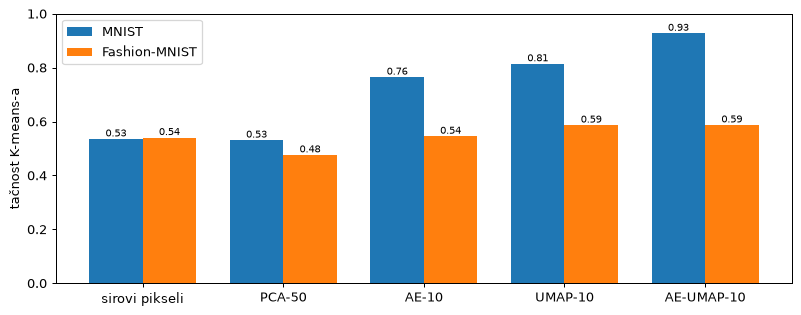

In [30]:
red_prostora = ["sirovi pikseli", "PCA-50", "AE-10", "UMAP-10", "AE-UMAP-10"]
fig, ax = plt.subplots(figsize=(9, 3.6))
for k, (s, naziv) in enumerate(SKUPOVI.items()):
    km_t = klasterovanje[s].query("algoritam == 'K-means'").set_index("prostor").tacnost.reindex(red_prostora)
    xs = np.arange(len(red_prostora)) + (k - 0.5) * 0.38
    ax.bar(xs, km_t.values, 0.38, label=naziv)
    for x_, v in zip(xs, km_t.values):
        ax.text(x_, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(range(len(red_prostora)), red_prostora); ax.set_ylim(0, 1)
ax.set_ylabel("tačnost K-means-a"); ax.legend()
plt.tight_layout(); plt.show()

**Tumačenje:**

- **Prostor određuje uspeh.** Na MNIST-u isti K-means daje 0.53 na pikselima, 0.53 u PCA-50, 0.76 u AE-10, 0.81 u
  UMAP-10 i 0.93 u AE-UMAP-10. Razlike između algoritama u istom prostoru su mnogo manje.
- **PCA ne pomaže klasterovanju.** PCA-50 zadržava bitne informacije (rezultat je isti kao na pikselima), ali ne
  olakšava razdvajanje klasa; za to je potrebna nelinearnost.
- **UMAP prostori su najbolji za svaki algoritam.** UMAP namerno zbija slične slike, pa granice među grupama postaju
  jasne. U PCA-50 grupe su razvučene i preklapaju se, pa ni GMM ni Ward ne mogu mnogo da poprave.
- **Najbolji rezultat:** MNIST K-means na AE-UMAP-10 (tačnost 0.93, ARI 0.86); Fashion GMM na UMAP-10 (0.61, ARI 0.51).
- **Fashion-MNIST ostaje oko 0.60** u svim nelinearnim prostorima, bez obzira na algoritam. Ograničenje nije
  reprezentacija, nego sličnost klasa.
- **ARI je uvek niži od tačnosti** i ponekad drugačije rangira rezultate bliske tačnosti. Na MNIST-u UMAP-10 + K-means
  (tačnost 0.814, ARI 0.774) i AE-10 + Ward (0.812, 0.724) imaju istu tačnost, ali ARI pokazuje da je UMAP-10
  klasterovanje „čistije" (greške su manje rasute). Na Fashion-u tačnost blago favorizuje AE-10 + GMM (0.590 naspram
  0.586), a ARI UMAP-10 + K-means (0.486 naspram 0.455).
- Na Fashion-u K-means na pikselima (0.540) daje više od K-means-a na PCA-50 (0.476). Pošto je pokrenuto sa jednim
  seed-om, to je verovatno posledica drugog lokalnog optimuma, a ne stvarna razlika.

Rezultati svih kombinacija za MNIST, prikazani na istoj 2D UMAP mapi (boje = pronađeni klasteri, ne prave klase):

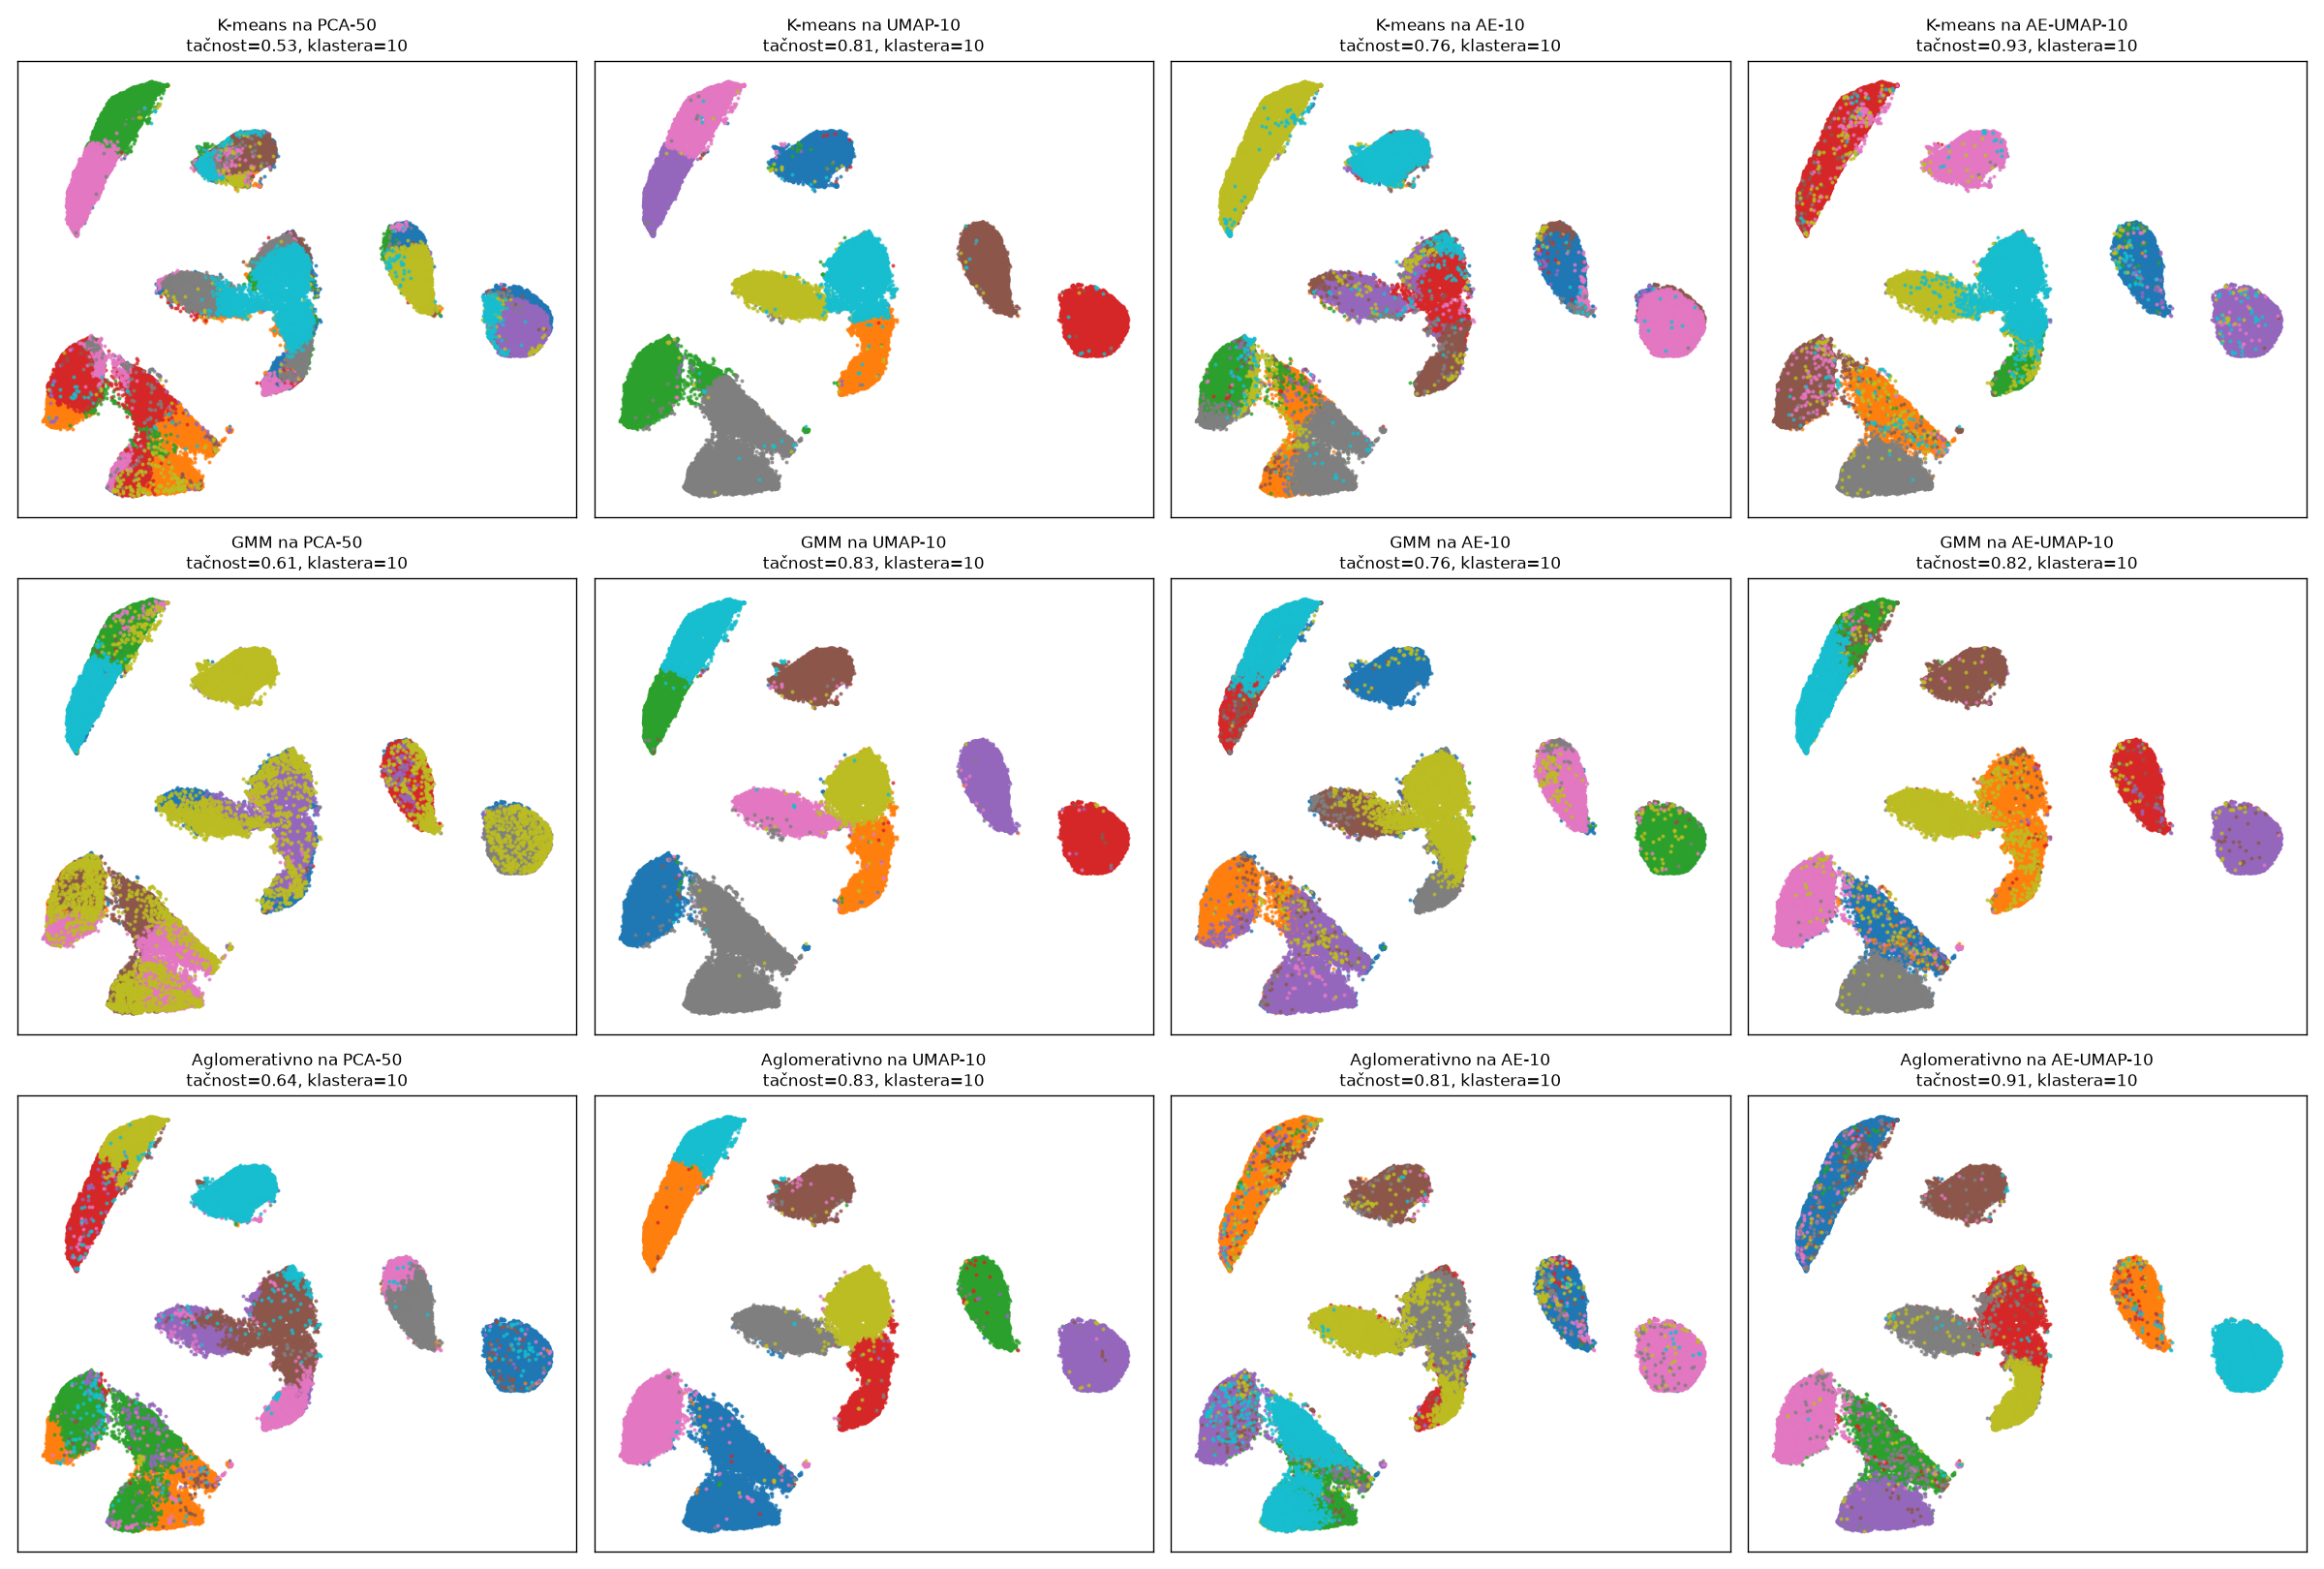

In [31]:
slika("mnist", "2b_klasteri_na_umap_mapi.png", 900)

## 4. Analiza grešaka (deo 3)

### 4.1 Koje klase se mešaju

Analiza je urađena za najbolju kombinaciju na svakom skupu. Deo 3 automatski pronalazi klase podeljene na više
klastera, klastere koji spajaju više klasa (bar 20% klastera), i za svaku zamenu određuje da li je **stvarno mešanje**
(slike su u zajedničkom klasteru) ili **artefakt uparivanja** (klasa je podeljena, pa je višak klaster dobio tuđu oznaku).
Matrica pokazuje koliko slika svake klase (redovi) završava u svakom klasteru (kolone):

**MNIST:** AE-UMAP-10 + K-means, tačnost 92.7%  
Klase podeljene na više klastera: nema  
Klasteri koji spajaju više klasa: K9 = {3, 5}

Najčešće zamene (prava klasa → klasa dodeljena klasteru):

- 5 -> 3: 30.0% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- 8 -> 3: 7.5% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- 4 -> 9: 6.3% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- 5 -> 8: 3.1% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- 7 -> 9: 2.6% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- 9 -> 3: 2.2% [stvarno mešanje (iste slike u zajedničkom klasteru)]

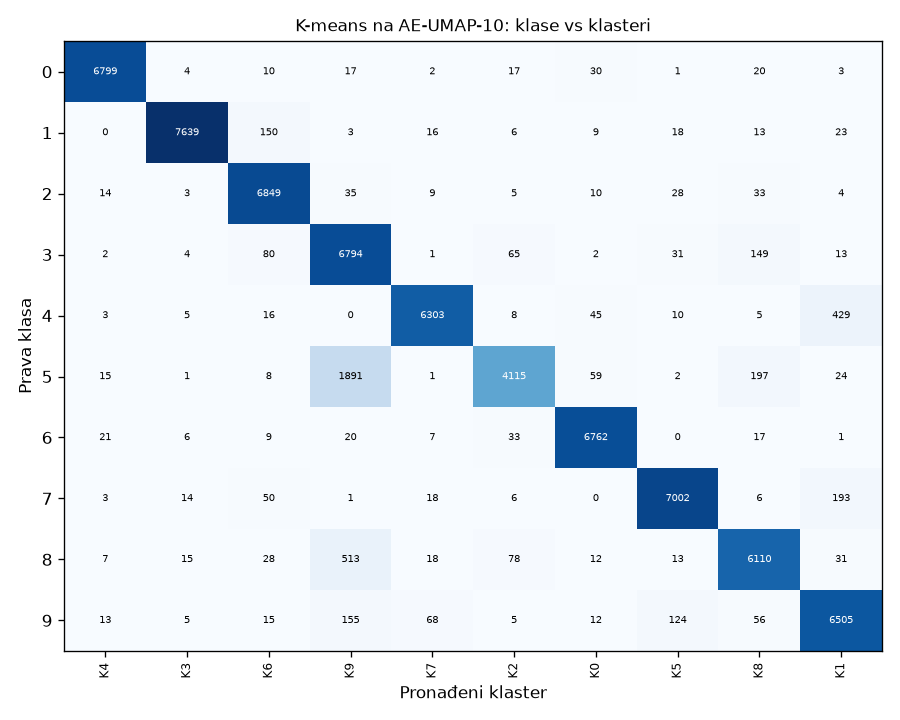

**Fashion-MNIST:** UMAP-10 + GMM, tačnost 61.2%  
Klase podeljene na više klastera: Džemper, Haljina  
Klasteri koji spajaju više klasa: K1 = {Džemper, Košulja}; K2 = {Sandala, Patika}; K5 = {Majica, Košulja}; K6 = {Sandala, Čizma}; K7 = {Džemper, Kaput, Košulja}; K8 = {Haljina, Kaput}; K9 = {Džemper, Kaput}

Najčešće zamene (prava klasa → klasa dodeljena klasteru):

- Sandala -> Patika: 51.9% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- Sandala -> Čizma: 47.4% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- Džemper -> Kaput: 32.2% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- Kaput -> Džemper: 30.0% [stvarno mešanje (iste slike u zajedničkom klasteru)]
- Džemper -> Košulja: 29.0% [artefakt uparivanja: klasa podeljena na više klastera]
- Haljina -> Sandala: 27.8% [artefakt uparivanja: klasa podeljena na više klastera]

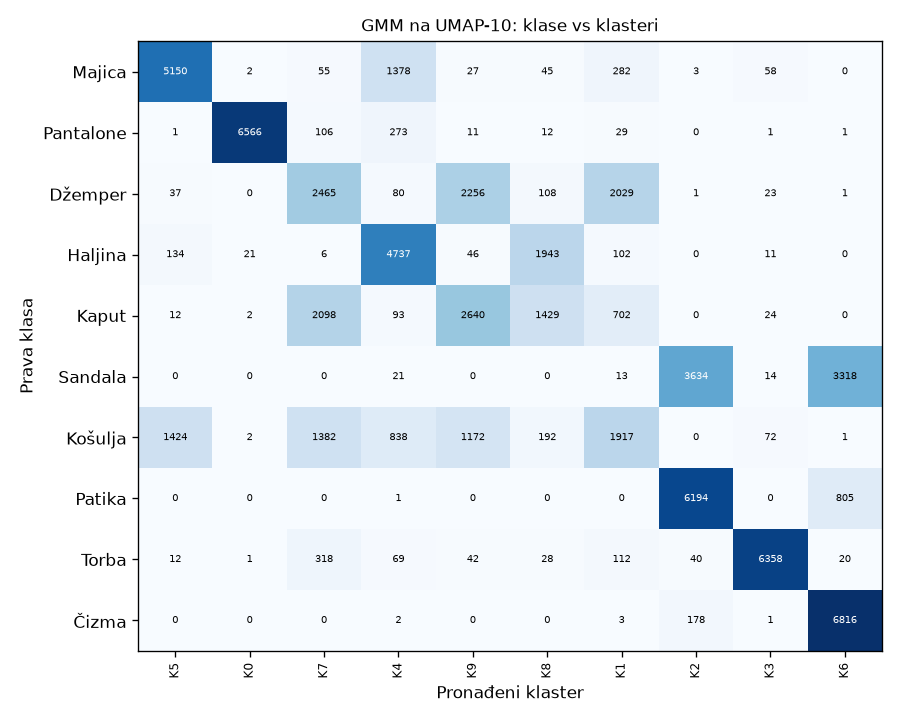

In [32]:
for s, naziv in SKUPOVI.items():
    d5 = sazetak[s]["deo3"]
    display(Markdown(
        f"**{naziv}:** {d5['najbolja_kombinacija'].replace('|', ' + ')}, tačnost {d5['najbolja_tacnost']:.1%}  \n"
        f"Klase podeljene na više klastera: {', '.join(d5['podeljene_klase']) or 'nema'}  \n"
        f"Klasteri koji spajaju više klasa: "
        + ("; ".join(f"{k} = {{{', '.join(v)}}}" for k, v in d5['spojeni_klasteri'].items()) or "nema")
        + "\n\nNajčešće zamene (prava klasa → klasa dodeljena klasteru):\n\n"
        + "\n".join(f"- {z}" for z in d5["najcesce_zamene"])))
    slika(s, "3a_matrica_klasteri.png", 600)

Udeo slika svake klase po klasi koja je dodeljena klasteru (dijagonala = tačno svrstane):

**MNIST**

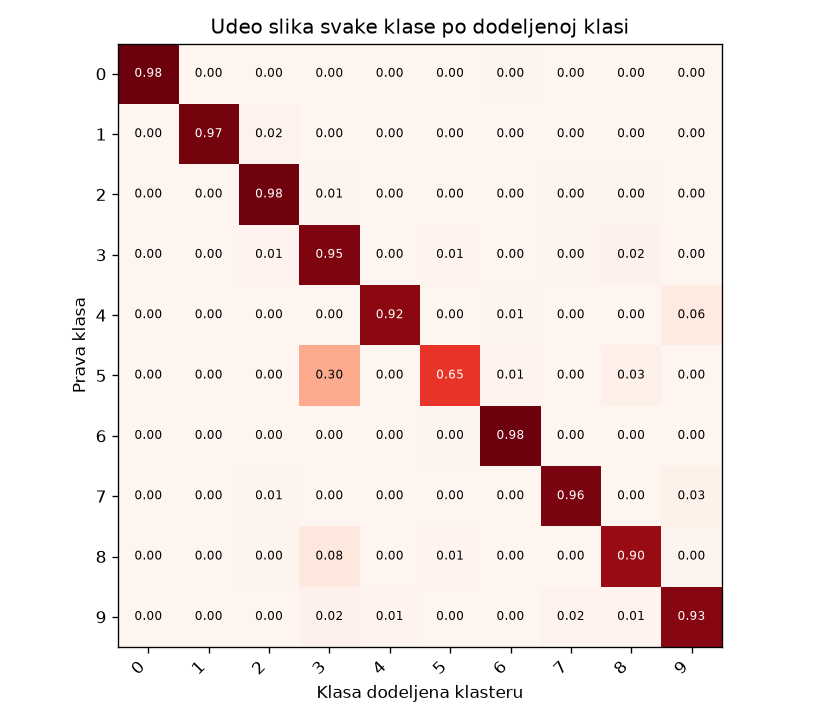

**Fashion-MNIST**

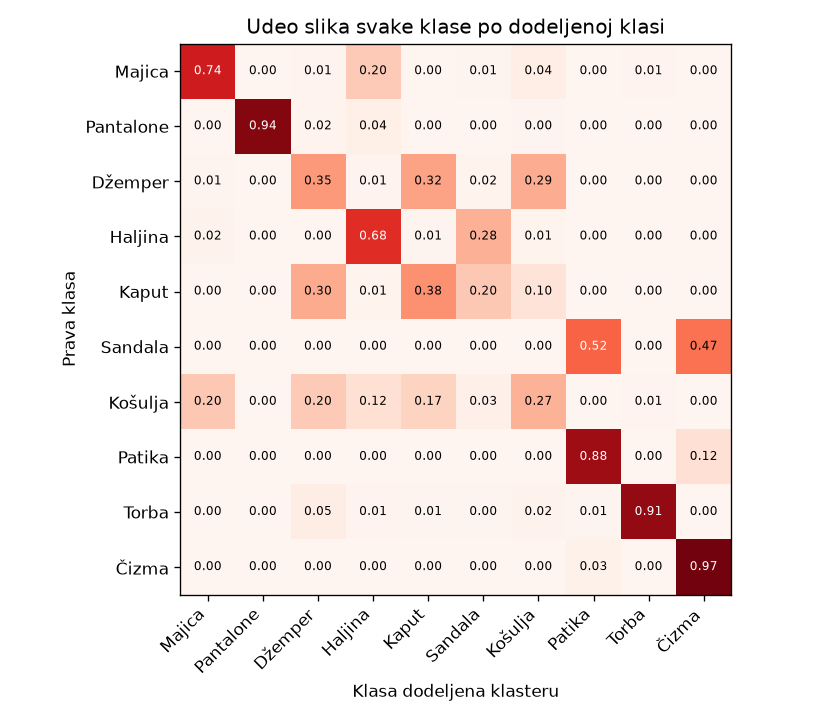

In [33]:
oba_skupa("3b_mesanje_klasa.png", 520)

Primeri pogrešno grupisanih slika za tri najčešće zamene:

**MNIST**

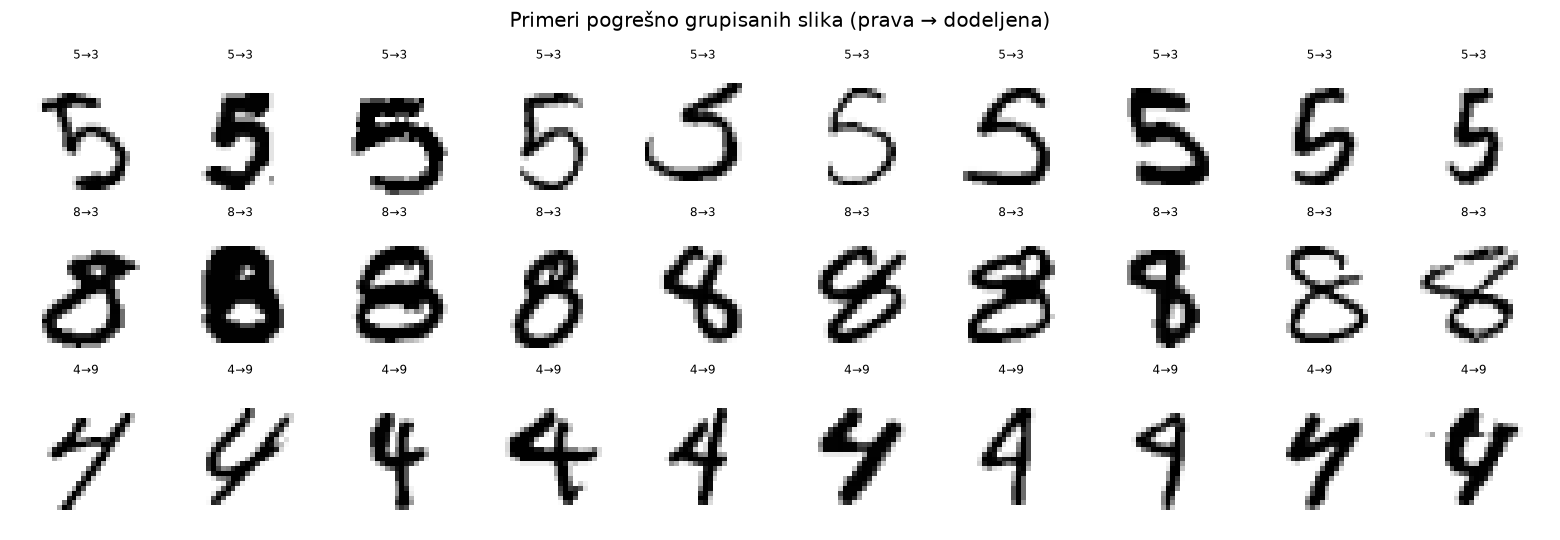

**Fashion-MNIST**

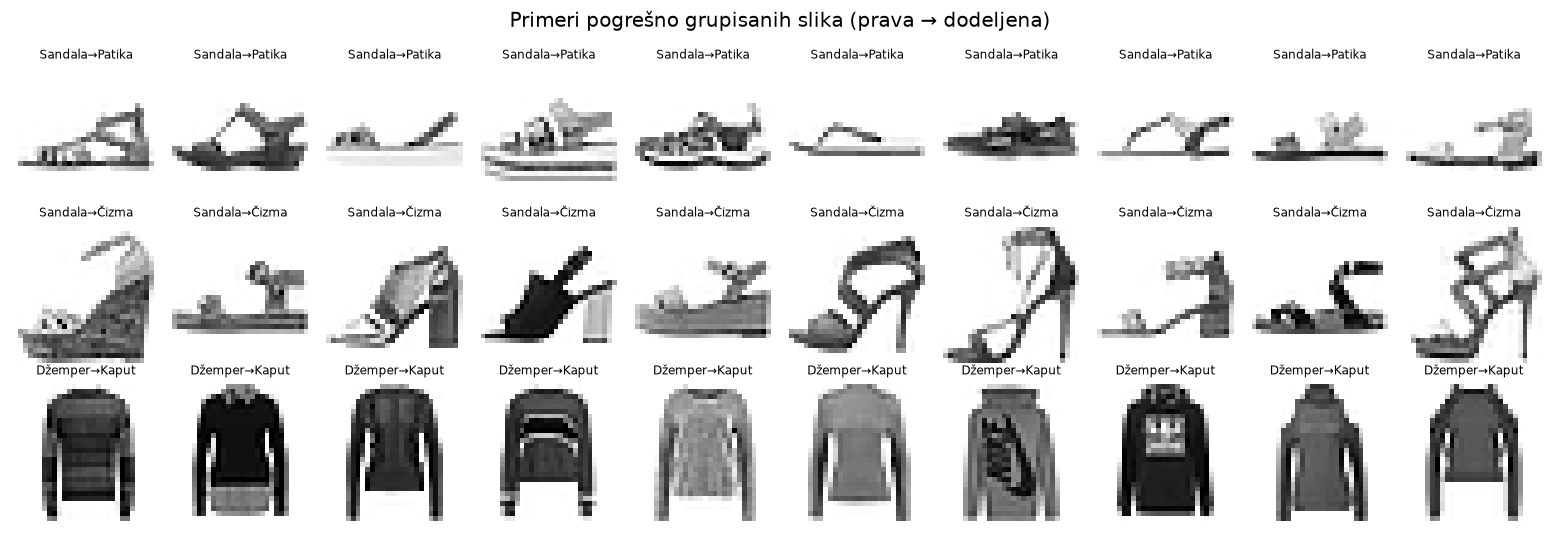

In [34]:
oba_skupa("3c_primeri_gresaka.png", 850)

**MNIST** (AE-UMAP-10 + K-means): nijedna klasa nije podeljena, a jedino veće stvarno mešanje je 5 → 3 (30%). Petica
i trojka imaju isti donji luk i razlikuju se samo u gornjem delu, pa ih algoritam drži u zajedničkom klasteru, iako su
na primerima to sasvim uredno napisane petice. Ostale zamene su male: 8 → 3 (osmice sa otvorenom levom stranom liče na
trojke) i 4 → 9 (četvorke sa zatvorenim vrhom liče na devetke).

**Fashion-MNIST** (UMAP-10 + GMM): greške imaju jasno vizuelno objašnjenje:
- **sandala → čizma:** sandale sa visokom petom ili platformom imaju siluetu čizme;
- **sandala → patika:** ravne sandale sa kaišićima liče na patike;
- **džemper ↔ kaput:** oba imaju duge rukave i sličnu siluetu, a na 28×28 rajsferšlus i dugmad se ne vide.

To nije propust algoritma: bez oznaka i na ovoj rezoluciji te klase se suštinski ne razlikuju.

### 4.2 Zamena nije uvek sličnost: artefakt uparivanja

Kao što je pokazano u odeljku 3.4, tačnost zahteva da svaki klaster dobije tačno jednu klasu. Kada algoritam **podeli**
jednu klasu na dva klastera i **spoji** dve druge u jedan, višak klaster mora da dobije oznaku klase koja je ostala bez
klastera. U demonstraciji na uzorku tako nastaje „1 → 9": jedinice su podeljene, a 4 i 9 dele klaster, pa je jedan
klaster jedinica dobio oznaku „9", iako nijedna od tih slika ne liči na devetku.

U trenutnim rezultatima to se vidi kod Fashion-a: „haljina → sandala" i „džemper → košulja" su artefakti (haljine i
džemperi su podeljeni na dva klastera), dok su „sandala → čizma" i „kaput → džemper" stvarno mešanje. Bez ovog
razlikovanja „haljina → sandala" bi izgledalo kao besmislena greška modela.

## 5. Zaključak

### 5.1 Glavni zaključci

1. **Reprezentacija određuje uspeh klasterovanja.** Na MNIST-u isti K-means daje 0.53 na pikselima, 0.81 u UMAP-10 i
   0.93 u AE-UMAP-10. Razlike između algoritama u istom prostoru su znatno manje od razlika između prostora.
2. **Nelinearnost pomaže, linearna kompresija ne.** Autoenkoder rekonstruiše 47–60% bolje od PCA sa istih 10
   dimenzija, a PCA-50 ne olakšava klasterovanje u odnosu na piksele.
3. **Naučene reprezentacije traže dovoljno podataka.** Na uzorku od 3.000 slika N2D ne donosi prednost u odnosu na
   običan UMAP, a na 70.000 slika je najbolji prostor. Autoenkoderu sa ~100.000 parametara treba mnogo primera.
4. **Fashion-MNIST je teži zbog prirode klasa.** Tačnost ostaje oko 0.60 bez obzira na metod i reprezentaciju, a
   greške su vizuelno opravdane (sandala/čizma, džemper/kaput). Klase koje su definisali ljudi ne poklapaju se uvek sa
   vizuelno sličnim grupama.
5. **Zamene treba tumačiti oprezno.** Brojevi kao „1 → 9" mogu biti artefakt uparivanja klastera sa klasama, a ne
   stvarna sličnost; zato deo 3 razlikuje podeljene klase od stvarnog mešanja.

### 5.2 Ograničenja

- Svi rezultati su dobijeni sa **jednim nasumičnim seed-om**; razlike od nekoliko procentnih poena između algoritama ne
  treba tumačiti kao značajne.
- Za sve algoritme zadat je **k = 10**, što koristi znanje o broju klasa. U pravom nenadgledanom zadatku taj broj ne bi
  bio poznat.
- Aglomerativno klasterovanje na 70.000 slika koristi Ward ograničen na **graf 15 najbližih suseda**, jer klasičan Ward
  zahteva oko 39 GB memorije.
- Parametri UMAP-a nisu sistematski podešavani (proverena je samo vrednost `n_neighbors` 15 umesto 30).

### 5.3 Pregled algoritama

| Algoritam | Tip | Glavna ideja | Prednost | Mana | U projektu (70.000 slika) |
|---|---|---|---|---|---|
| PCA | dim. redukcija | sopstveni vektori kovarijanse | brz, egzaktan, tumačiv | samo linearno | PCA-50 ~83–86% varijanse; ne pomaže klasterovanju |
| t-SNE | vizuelizacija | verovatnoće suseda, t-raspodela, KL | lepo razdvaja grupe | spor, samo 2D | jasno razdvaja 10 cifara |
| UMAP | dim. redukcija | graf suseda, unakrsna entropija | brz, radi u 10D | zavisi od parametara | najbolji prostor za klasterovanje |
| Autoenkoder | dim. redukcija | konv. mreža sabija i vraća sliku | nelinearan | treba mnogo podataka | MSE 47–60% manji od PCA-10 |
| N2D | dim. redukcija | UMAP na latentnom prostoru AE | najbolje osobine | treba ceo skup | **0.93** (MNIST, K-means) |
| K-means | klasterovanje | najbliži od *k* centara | jednostavan, brz | okrugle grupe | 0.93 na N2D (MNIST) |
| GMM | klasterovanje | mešavina Gausovih, EM | izdužene grupe | mnogo parametara | **0.61** na UMAP-10 (Fashion) |
| Ward | klasterovanje | spajanje odozdo naviše | hijerarhija, bez nasumičnosti | memorija n² | 0.92 na N2D (MNIST) |
| Tačnost | evaluacija | Mađarsko uparivanje 1-na-1 | intuitivna | artefakt uparivanja | glavna mera |
| ARI | evaluacija | slaganje parova, korigovano za slučajnost | stroga, bez uparivanja | manje intuitivna | uvek niži od tačnosti |

## 6. Literatura

**Podaci**

1. LeCun, Y., Bottou, L., Bengio, Y., Haffner, P. (1998). Gradient-based learning applied to document recognition.
   *Proceedings of the IEEE*, 86(11), 2278–2324. (MNIST)
2. Xiao, H., Rasul, K., Vollgraf, R. (2017). Fashion-MNIST: a novel image dataset for benchmarking machine learning
   algorithms. *arXiv:1708.07747*.

**Smanjenje dimenzionalnosti**

3. Pearson, K. (1901). On lines and planes of closest fit to systems of points in space. *Philosophical Magazine*,
   2(11), 559–572. (PCA)
4. van der Maaten, L., Hinton, G. (2008). Visualizing data using t-SNE. *Journal of Machine Learning Research*, 9,
   2579–2605.
5. McInnes, L., Healy, J., Melville, J. (2018). UMAP: Uniform Manifold Approximation and Projection for dimension
   reduction. *arXiv:1802.03426*.
6. Kobak, D., Linderman, G. C. (2021). Initialization is critical for preserving global data structure in both t-SNE
   and UMAP. *Nature Biotechnology*, 39, 156–157.
7. Hinton, G. E., Salakhutdinov, R. R. (2006). Reducing the dimensionality of data with neural networks. *Science*,
   313(5786), 504–507. (autoenkoder)
8. McConville, R., Santos-Rodríguez, R., Piechocki, R. J., Craddock, I. (2019). N2D: (Not Too) Deep clustering via
   clustering the local manifold of an autoencoded embedding. *arXiv:1908.05968*.

**Klasterovanje i mere kvaliteta**

9. Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory*, 28(2), 129–137.
   (K-means)
10. Dempster, A. P., Laird, N. M., Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm.
    *Journal of the Royal Statistical Society, Series B*, 39(1), 1–38. (GMM)
11. Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical
    Association*, 58(301), 236–244.
12. Kuhn, H. W. (1955). The Hungarian method for the assignment problem. *Naval Research Logistics Quarterly*, 2(1–2),
    83–97. (tačnost)
13. Hubert, L., Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2(1), 193–218. (ARI)